# Task 3 — Multimodal Clustering: Jenis Material dari Citra Mikrostruktur + Spektrum Komposisi

**Proyek UTS Deep Learning:** *Hands-on Deep Learning: Classification, Regression, and Clustering*
**Notebook:** `task3_multimodal_clustering.ipynb` (satu file, dijalankan **lokal** dengan *Run All*; GPU NVIDIA dipakai otomatis bila tersedia, jika tidak memakai CPU)
**Reproduksi satu perintah** (jalankan dari folder yang berisi `dataset/`): `jupyter nbconvert --to notebook --execute --inplace task3_multimodal_clustering.ipynb` (seed dan versi library dicetak di Section 2).

---

# SECTION 1 — Project Overview

## Tujuan clustering
Mengelompokkan **36.000 sampel material** menjadi jenis-jenis material **tanpa label**, memakai dua modality yang dipasangkan per sampel:
1. **Citra mikrostruktur** (64×64, dari mikroskop M1 atau M2).
2. **Spektrum komposisi** (128 kanal).

Hasil dinilai dosen dengan **Adjusted Rand Index (ARI)** terhadap jenis material sebenarnya (disimpan dosen, tidak dibagikan). Nomor cluster boleh bebas. Label tersembunyi **tidak** dipakai untuk apa pun di notebook ini.

## Mengapa multimodal?
Satu modality sering tidak cukup membedakan semua jenis material: dua jenis bisa punya spektrum hampir sama tetapi mikrostruktur berbeda, atau sebaliknya. Pendekatan multimodal mempelajari **representasi (embedding) per modality**, lalu **menggabungkan** keduanya (*fusion*) sebelum clustering, sehingga cluster memanfaatkan informasi yang saling melengkapi. Notebook ini juga menunjukkan **apa yang hilang bila hanya satu modality dipakai**.

## Pembagian kontribusi
| Bagian | Penanggung jawab |
|---|---|
| EDA gambar, preprocessing gambar, *image representation learning*, **menghasilkan image embedding** | **Anggota 1** |
| EDA spektrum, preprocessing spektrum, **spectrum representation learning**, **multimodal fusion**, **clustering (KMeans/GMM + DEC)**, pemilihan jumlah cluster, UMAP/t-SNE, evaluasi, analisis | **Anggota 2** |

> Bagian gambar **bukan** hasil kerja Anggota 2: notebook ini hanya **memuat** image embedding dari Anggota 1 (Section 6) dan hanya menampilkan contoh gambar sebagai konteks (Section 4A).

## Alur metode
1. **EDA & preprocessing spektrum** — buang spike, koreksi baseline, normalisasi per sampel (tanpa label, tanpa statistik global, jadi tanpa kebocoran).
2. **Spectrum representation learning** — *autoencoder* vs *contrastive encoder* dengan augmentasi yang meniru distorsi spektrum (geseran, baseline, spike, noise), dibandingkan dengan PCA.
3. **Integrasi image embedding Anggota 1** dan **fusion** (beberapa strategi).
4. **Clustering:** KMeans/GMM dan **Deep Embedded Clustering (DEC)**.
5. **Jumlah cluster** dengan beberapa kriteria, **UMAP/t-SNE**, evaluasi (ARI bila referensi tersedia; metrik internal dan kestabilan), analisis, ekspor `cluster.csv`.

# SECTION 2 — Library Installation & Import

In [54]:
# Instalasi hanya jika library belum ada. Untuk GPU NVIDIA lokal, pasang PyTorch versi CUDA lebih dulu (pytorch.org/get-started/locally).
import importlib, subprocess, sys

for pkg, mod in [("torch", "torch"), ("scikit-learn", "sklearn"), ("pandas", "pandas"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn"), ("umap-learn", "umap")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f"Memasang {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [55]:
import os, re, sys, json, time, random, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, r2_score)
from scipy.ndimage import gaussian_filter1d
from scipy import ndimage
from scipy.signal import find_peaks
from scipy.stats import chi2_contingency

import torch
import torch.nn as nn
import torch.nn.functional as F
import umap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 100

# ---- Random seed (reproducibility) ----
SEED = 42
def set_seed(seed: int = SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# ---- GPU configuration ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Versi   :", f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | torch {torch.__version__} | seed {SEED}")
print("Device  :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (training DL lebih lambat; bila terlalu lama, kecilkan CL_EPOCHS, AE_EPOCHS, dan DEC_*_EPOCHS di Section 3)")

Versi   : python 3.11.9 | numpy 2.4.6 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0+cpu | seed 42
Device  : cpu | CPU (training DL lebih lambat; bila terlalu lama, kecilkan CL_EPOCHS, AE_EPOCHS, dan DEC_*_EPOCHS di Section 3)


# SECTION 3 — Configuration & Dataset Loading

Notebook ini dijalankan **di komputer lokal**. Letakkan folder `dataset/` **di samping notebook** (atau satu tingkat di atasnya, `../dataset/`) berisi:
* `clustering_meta.csv`, dan
* `clustering.npz` (±150 MB, berisi `gambar` dan `spektrum`) **atau** `clustering_tanpa_gambar.npz` (±8 MB, cukup untuk bagian Anggota 2; contoh gambar di Section 4A dilewati).

Hanya array `spektrum` yang dibaca ke memori untuk pemrosesan. Hasil antara (embedding, bobot model, assignment) disimpan di folder `outputs/` sehingga **tidak perlu training ulang** pada run berikutnya (set `RETRAIN = True` untuk melatih ulang).

In [56]:
# ---------------- KONFIGURASI ----------------
CANDIDATE_DIRS = ["dataset", "../dataset", "."]          # relatif terhadap folder notebook
NPZ_NAMES      = ["clustering.npz", "clustering_tanpa_gambar.npz"]     # nama kedua = salinan tanpa array gambar
META_FILE      = "clustering_meta.csv"
N_EXPECTED     = 36000

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RETRAIN = False                # True: abaikan cache bobot/embedding dan latih ulang semua model

# --- Preprocessing spektrum ---
SPIKE_MAD  = 7.0               # spike jika |selisih ke rata-rata tetangga| > 7 x MAD (ambang di jurang antara noise dan spike, lihat 4.6)
BASE_DEG   = 3                 # derajat polinomial baseline
BASE_ITERS = 60                # iterasi pemotongan baseline (ModPoly)

# --- Representasi spektrum ---
EMB_DIM    = 32                # dimensi embedding spektrum
SHIFT_MAX  = 6.0               # augmentasi geser maksimum (kanal); geseran nyata kira-kira +-5 kanal (lihat 5.4)
TAU        = 0.2               # temperatur NT-Xent
CL_EPOCHS, AE_EPOCHS = 60, 60
BATCH, LR  = 1024, 1e-3

# --- Clustering ---
K_RANGE    = list(range(2, 13))
N_INIT     = 10
N_STAB     = 5                 # ulangan resampling untuk kestabilan
DEC_LATENT, DEC_PRETRAIN_EPOCHS, DEC_EPOCHS = 10, 60, 80
DEC_TOL, DEC_GAMMA, DEC_LR = 0.001, 0.1, 5e-4

# --- Embedding gambar Anggota 1 (format harus disepakati bersama; lihat Section 6) ---
IMG_EMB_FILE = "embedding_gambar.npz"
IMG_ID_KEY, IMG_EMB_KEY = "id_sampel", "embedding"

# --- Label referensi (hanya untuk evaluasi bila tersedia; tidak pernah dipakai untuk training/clustering) ---
REF_LABEL_FILE = "referensi_label.csv"      # kolom id_sampel, label. Biasanya TIDAK ada pada mahasiswa.
print("OUTPUT_DIR =", OUTPUT_DIR.resolve())

OUTPUT_DIR = C:\Users\Echa\Documents\UTS_DL_Clustering\kode\outputs


In [57]:
def find_data():
    for d in CANDIDATE_DIRS:
        for n in NPZ_NAMES:
            if (Path(d) / n).exists() and (Path(d) / META_FILE).exists():
                return Path(d), n
    return None, None

DATA_DIR, NPZ_NAME = find_data()
assert DATA_DIR is not None, (f"{NPZ_NAMES} + {META_FILE} tidak ditemukan di {CANDIDATE_DIRS}. "
                              "Taruh kedua berkas di folder dataset/ di samping notebook, lalu jalankan ulang cell ini.")
NPZ_PATH, META_PATH = DATA_DIR / NPZ_NAME, DATA_DIR / META_FILE
print("DATA_DIR =", DATA_DIR.resolve(), "| berkas array:", NPZ_NAME)

# ---- Struktur folder ----
for f in sorted(DATA_DIR.iterdir()):
    if f.is_file():
        print(f"   {f.name:<34s} {f.stat().st_size / 1e6:9.2f} MB")

# ---- Struktur isi npz: baca hanya header (tanpa memuat array besar) ----
def npz_info(path):
    info = {}
    with zipfile.ZipFile(path) as z:
        for name in z.namelist():
            if name.endswith(".npy"):
                with z.open(name) as fh:
                    ver = np.lib.format.read_magic(fh)
                    rd = np.lib.format.read_array_header_1_0 if ver == (1, 0) else np.lib.format.read_array_header_2_0
                    shape, _, dtype = rd(fh)
                info[name[:-4]] = (shape, np.dtype(dtype))
    return info

NPZ_INFO = npz_info(NPZ_PATH)
print("\nIsi npz:", {k: f"{v[0]} {v[1]}" for k, v in NPZ_INFO.items()})
assert "spektrum" in NPZ_INFO, f"array 'spektrum' tidak ada; kunci tersedia: {list(NPZ_INFO)}"
HAS_IMAGES = "gambar" in NPZ_INFO

meta = pd.read_csv(META_PATH)
print("\nMeta:", meta.shape, "| kolom:", list(meta.columns)); print(meta.dtypes.to_string())
print(meta.head(3).to_string(index=False))

DATA_DIR = C:\Users\Echa\Documents\UTS_DL_Clustering\kode | berkas array: clustering.npz
   clustering.npz                        130.26 MB
   clustering_meta.csv                     0.60 MB
   task3_multimodal_clustering.ipynb       1.81 MB
   task3_multimodal_clustering.ipynb.ipynb      0.12 MB

Isi npz: {'gambar': '(36000, 64, 64) uint8', 'spektrum': '(36000, 128) float16'}

Meta: (36000, 3) | kolom: ['indeks', 'id_sampel', 'mikroskop']
indeks       int64
id_sampel      str
mikroskop      str
 indeks id_sampel mikroskop
      0   S966119        M1
      1   S315633        M2
      2   S805122        M1


In [58]:
# ---- Identifikasi ID sampel & pemeriksaan jumlah/pairing ----
N = len(meta)
IDS = meta["id_sampel"].astype(str).to_numpy()
MIC = (meta["mikroskop"].to_numpy() == "M2").astype(int)            # M1 = 0, M2 = 1

assert set(meta["mikroskop"].unique()) == {"M1", "M2"}, meta["mikroskop"].unique()
assert meta["id_sampel"].is_unique, "id_sampel tidak unik"
assert (meta["indeks"].to_numpy() == np.arange(N)).all(), "kolom 'indeks' harus = 0..N-1 (baris i meta <-> array ke-i)"
assert all(re.fullmatch(r"S\d{6}", s) for s in IDS), "format id_sampel tidak seperti S123456"
assert NPZ_INFO["spektrum"][0][0] == N, f"jumlah spektrum {NPZ_INFO['spektrum'][0][0]} != jumlah baris meta {N}"
if HAS_IMAGES:
    assert NPZ_INFO["gambar"][0][0] == N, "jumlah gambar != jumlah baris meta"
if N != N_EXPECTED:
    print(f"PERINGATAN: N = {N}, bukan {N_EXPECTED}")

print(f"N sampel = {N} | ID unik | indeks = 0..{N - 1} | M1: {int((MIC == 0).sum())}, M2: {int((MIC == 1).sum())}")
print("Pairing: baris i pada meta = gambar[i] = spektrum[i] (kunci pairing: kolom 'indeks'/urutan baris; ID = id_sampel).")

npz = np.load(NPZ_PATH)
SPEC_RAW = npz["spektrum"]                       # (N, 128) float16, hanya array ini yang dimuat ke memori
X_RAW = SPEC_RAW.astype(np.float32)
L = X_RAW.shape[1]
print(pd.DataFrame({"array": ["spektrum"] + (["gambar"] if HAS_IMAGES else []),
                    "shape": [SPEC_RAW.shape] + ([NPZ_INFO["gambar"][0]] if HAS_IMAGES else []),
                    "dtype": [str(SPEC_RAW.dtype)] + ([str(NPZ_INFO["gambar"][1])] if HAS_IMAGES else [])}).to_string(index=False))

N sampel = 36000 | ID unik | indeks = 0..35999 | M1: 21636, M2: 14364
Pairing: baris i pada meta = gambar[i] = spektrum[i] (kunci pairing: kolom 'indeks'/urutan baris; ID = id_sampel).
   array           shape   dtype
spektrum    (36000, 128) float16
  gambar (36000, 64, 64)   uint8


# SECTION 4 — Exploratory Data Analysis

## Bagian A — Image EDA
> **EDA gambar adalah tanggung jawab Anggota 1.** Bagian ini hanya menampilkan contoh gambar dan informasi dasar sebagai konteks; tempelkan hasil EDA lengkap Anggota 1 (distorsi rotasi, skala, kecerahan, perbedaan mikroskop) pada cell Markdown di bawahnya.

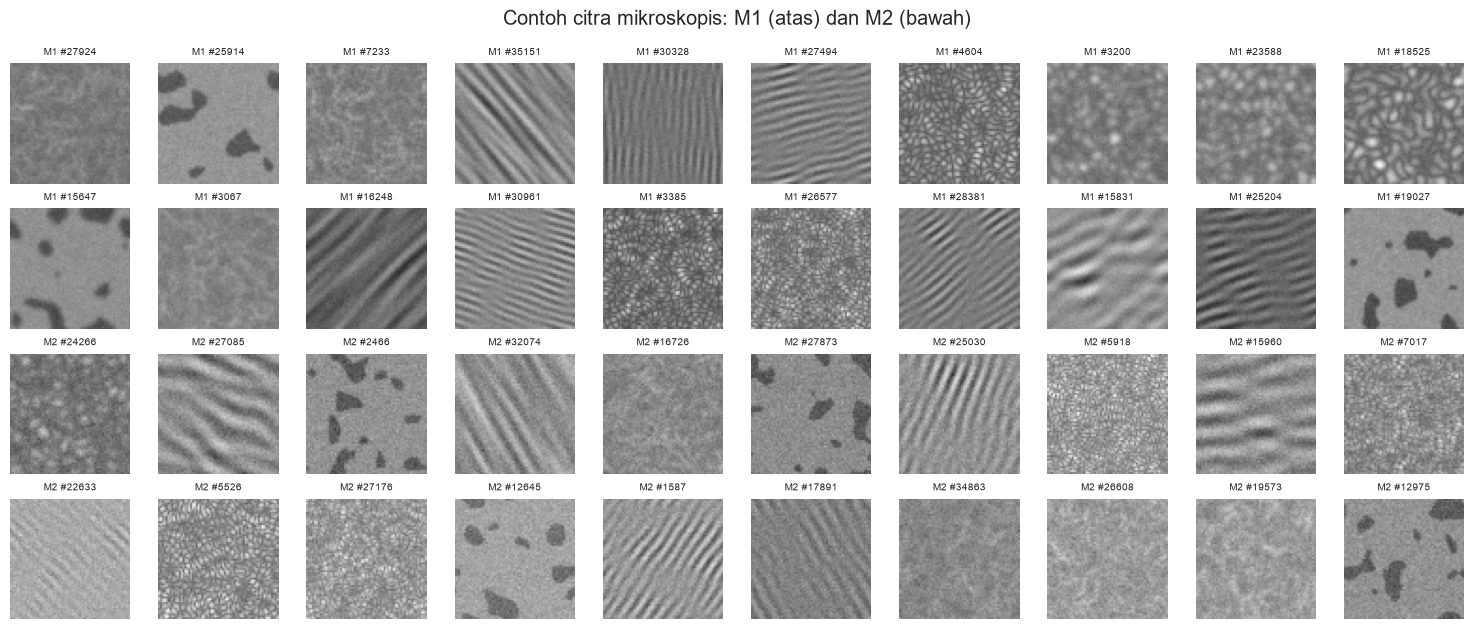

Statistik gambar per mikroskop:
 mikroskop                M1           M2
kecerahan mean   127.800003   146.070007
          std     12.060000    11.020000
kontras   mean    19.700001    19.900000
          std      5.380000     4.650000
ketajaman mean  1305.560059  2304.949951
          std   1491.540039  1239.319946
Estimasi derau (subsampel):
            mean   std
mikroskop            
M1         3.86  2.62
M2         5.78  1.82


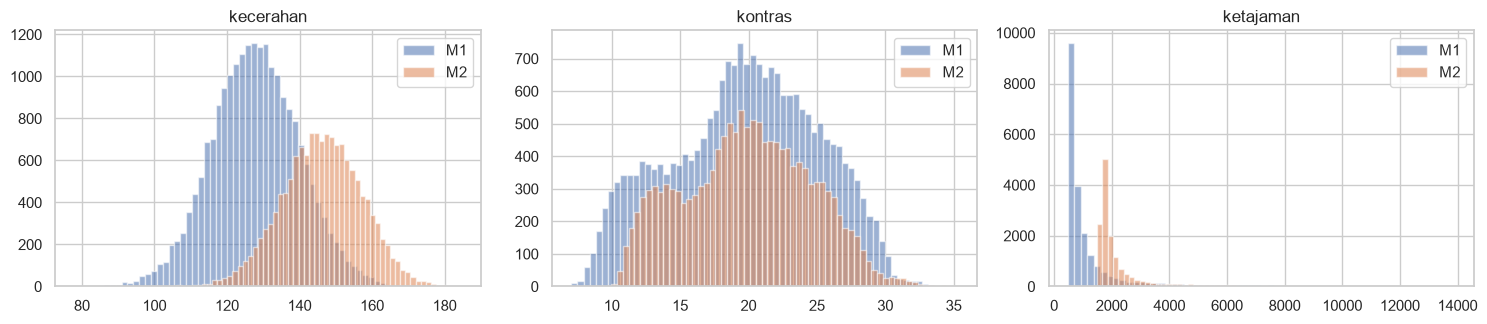

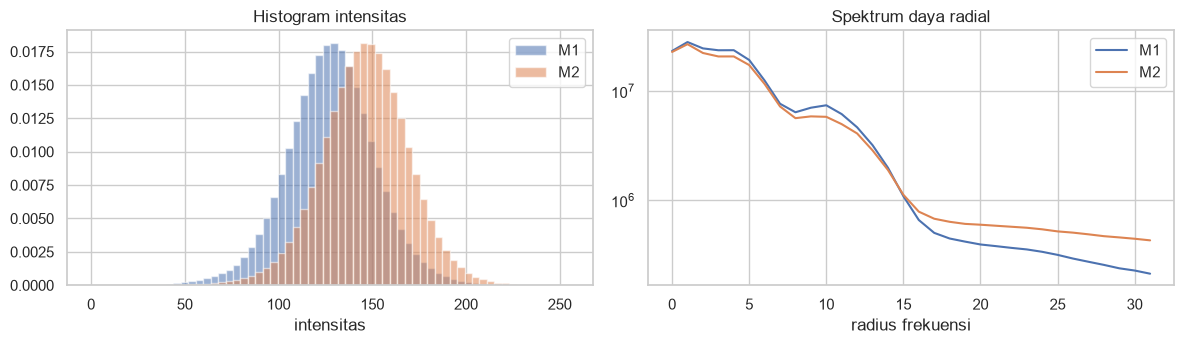

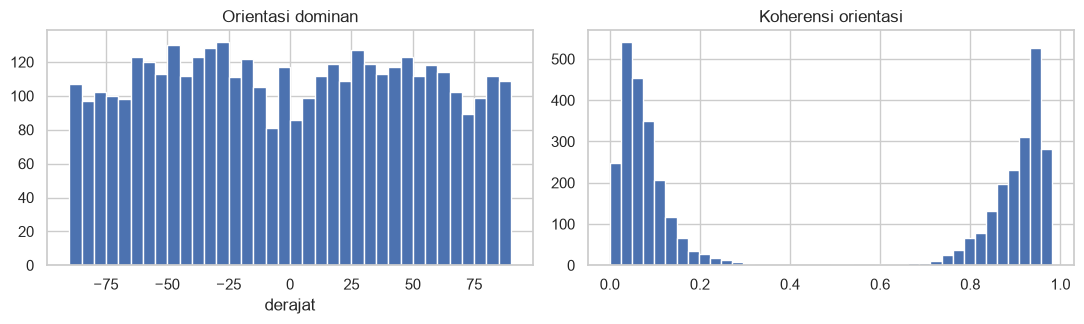

Koherensi orientasi rata-rata = 0.472
Varians PCA gambar PC1-5: [0.345 0.003 0.003 0.003 0.003]
|korelasi| PC1-kecerahan: 1.0
|korelasi| PC1-mikroskop: 0.614
NMI KMeans PCA mentah vs mikroskop: 0.168


In [59]:
# ---- 4.A EDA gambar mikroskopis (Anggota 1; tanpa label material) ----
if HAS_IMAGES:
    GAMBAR = npz["gambar"]  # (N, 64, 64), uint8
    assert GAMBAR.shape[0] == N, "jumlah gambar tidak cocok dengan metadata"
    rng_img = np.random.default_rng(SEED)

    # 4.A.1 Contoh gambar per mikroskop
    fig, axes = plt.subplots(4, 10, figsize=(15, 6.4))
    for r, (nm, v) in enumerate([("M1", 0), ("M2", 1)]):
        pool = np.where(MIC == v)[0]
        pick = rng_img.choice(pool, min(20, len(pool)), replace=False)
        for j, idx in enumerate(pick):
            ax = axes[2*r + j//10, j%10]
            ax.imshow(GAMBAR[idx], cmap="gray", vmin=0, vmax=255)
            ax.axis("off"); ax.set_title(f"{nm} #{idx}", fontsize=7)
    plt.suptitle("Contoh citra mikroskopis: M1 (atas) dan M2 (bawah)")
    plt.tight_layout(); plt.show()

    # 4.A.2 Statistik kecerahan, kontras, ketajaman, dan estimasi derau
    IMG_RAW_FLOAT = GAMBAR.astype(np.float32)
    img_mean = IMG_RAW_FLOAT.mean((1, 2))
    img_std = IMG_RAW_FLOAT.std((1, 2))
    lap = (IMG_RAW_FLOAT[:, 1:-1, 1:-1] * 4
           - IMG_RAW_FLOAT[:, :-2, 1:-1] - IMG_RAW_FLOAT[:, 2:, 1:-1]
           - IMG_RAW_FLOAT[:, 1:-1, :-2] - IMG_RAW_FLOAT[:, 1:-1, 2:])
    img_sharp = lap.var((1, 2))
    noise_idx = rng_img.choice(N, min(4000, N), replace=False)
    img_noise = np.array([
        np.median(np.abs(IMG_RAW_FLOAT[i] - ndimage.median_filter(IMG_RAW_FLOAT[i], size=3)))
        for i in noise_idx
    ], dtype=np.float32)
    IMG_STAT = pd.DataFrame({
        "kecerahan": img_mean, "kontras": img_std, "ketajaman": img_sharp,
        "mikroskop": np.where(MIC == 1, "M2", "M1")
    })
    IMG_STAT_NOISE = pd.DataFrame({"derau": img_noise,
        "mikroskop": np.where(MIC[noise_idx] == 1, "M2", "M1")})
    print("Statistik gambar per mikroskop:\n", IMG_STAT.groupby("mikroskop").agg(["mean", "std"]).round(2).T)
    print("Estimasi derau (subsampel):\n", IMG_STAT_NOISE.groupby("mikroskop")["derau"].agg(["mean", "std"]).round(2))
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
    for j, col in enumerate(["kecerahan", "kontras", "ketajaman"]):
        for nm in ["M1", "M2"]:
            ax[j].hist(IMG_STAT.loc[IMG_STAT.mikroskop == nm, col], bins=60, alpha=.55, label=nm)
        ax[j].set_title(col); ax[j].legend()
    plt.tight_layout(); plt.show()

    # 4.A.3 Histogram intensitas dan spektrum daya radial
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    yy, xx = np.indices((GAMBAR.shape[1], GAMBAR.shape[2]))
    cy, cx = (GAMBAR.shape[1]-1)/2, (GAMBAR.shape[2]-1)/2
    rr = np.hypot(yy-cy, xx-cx).astype(int).ravel()
    for v, nm in [(0, "M1"), (1, "M2")]:
        pool = np.where(MIC == v)[0]
        pick = rng_img.choice(pool, min(2000, len(pool)), replace=False)
        ax[0].hist(GAMBAR[pick].ravel(), bins=64, alpha=.55, density=True, label=nm)
        centered = IMG_RAW_FLOAT[pick] - IMG_RAW_FLOAT[pick].mean((1,2), keepdims=True)
        power = np.abs(np.fft.fftshift(np.fft.fft2(centered, axes=(1,2)), axes=(1,2)))**2
        sums = np.bincount(rr, weights=power.mean(0).ravel())
        counts = np.bincount(rr)
        radial = sums / np.maximum(counts, 1)
        ax[1].semilogy(radial[:min(32, len(radial))], label=nm)
    ax[0].set(title="Histogram intensitas", xlabel="intensitas"); ax[0].legend()
    ax[1].set(title="Spektrum daya radial", xlabel="radius frekuensi"); ax[1].legend()
    plt.tight_layout(); plt.show()

    # 4.A.4 Orientasi dominan dan koherensi structure tensor
    def img_dominant_orientation(image):
        gy, gx = np.gradient(ndimage.gaussian_filter(image.astype(np.float32), 1.0))
        jxx, jyy, jxy = (gx*gx).sum(), (gy*gy).sum(), (gx*gy).sum()
        coh = np.hypot(jxx-jyy, 2*jxy) / (jxx+jyy+1e-9)
        angle = 0.5*np.degrees(np.arctan2(2*jxy, jxx-jyy))
        return angle, coh
    ori_idx = rng_img.choice(N, min(4000, N), replace=False)
    IMG_ORIENTATION = np.asarray([img_dominant_orientation(IMG_RAW_FLOAT[i]) for i in ori_idx])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    ax[0].hist(IMG_ORIENTATION[:,0], bins=36); ax[0].set(title="Orientasi dominan", xlabel="derajat")
    ax[1].hist(IMG_ORIENTATION[:,1], bins=40); ax[1].set(title="Koherensi orientasi")
    plt.tight_layout(); plt.show()
    print(f"Koherensi orientasi rata-rata = {IMG_ORIENTATION[:,1].mean():.3f}")

    # 4.A.5 PCA mentah: cek apakah variasi awal mengikuti kecerahan/mikroskop
    IMG_SUB = rng_img.choice(N, min(8000, N), replace=False)
    IMG_PCA_RAW = PCA(n_components=min(10, len(IMG_SUB), GAMBAR.shape[1]*GAMBAR.shape[2]), random_state=SEED)
    IMG_SCORE_RAW = IMG_PCA_RAW.fit_transform(IMG_RAW_FLOAT.reshape(N, -1)[IMG_SUB])
    print("Varians PCA gambar PC1-5:", IMG_PCA_RAW.explained_variance_ratio_[:5].round(3))
    print("|korelasi| PC1-kecerahan:", round(abs(np.corrcoef(IMG_SCORE_RAW[:,0], img_mean[IMG_SUB])[0,1]), 3))
    print("|korelasi| PC1-mikroskop:", round(abs(np.corrcoef(IMG_SCORE_RAW[:,0], MIC[IMG_SUB])[0,1]), 3))
    IMG_KM_RAW = KMeans(4, n_init=5, random_state=SEED).fit_predict(StandardScaler().fit_transform(IMG_SCORE_RAW))
    print("NMI KMeans PCA mentah vs mikroskop:", round(normalized_mutual_info_score(IMG_KM_RAW, MIC[IMG_SUB]), 3))
else:
    print("Array gambar tidak tersedia; EDA gambar dilewati. Notebook tetap dapat menjalankan analisis spektrum.")


**Interpretasi EDA gambar (Anggota 1).** Gunakan tabel dan grafik di atas untuk membandingkan kecerahan, kontras, ketajaman, derau, orientasi, serta keterkaitan PC1 dengan mikroskop. M1/M2 hanya dipakai untuk diagnosis *domain shift*, bukan sebagai label jenis material. Isi kesimpulan berdasarkan angka hasil eksekusi, jangan mengarang nilai sebelum notebook dijalankan.


## Bagian B — Spectrum EDA

bentuk                                           (36000, 128)
dtype asli                                            float16
NaN                                                         0
Inf                                                         0
min                                                 -1.663086
max                                                  6.152344
rata-rata                                            0.448439
std                                                  0.406897
% nilai negatif                                      9.066536
jumlah per sampel (p1 / median / p99)    [-15.1, 57.4, 130.3]


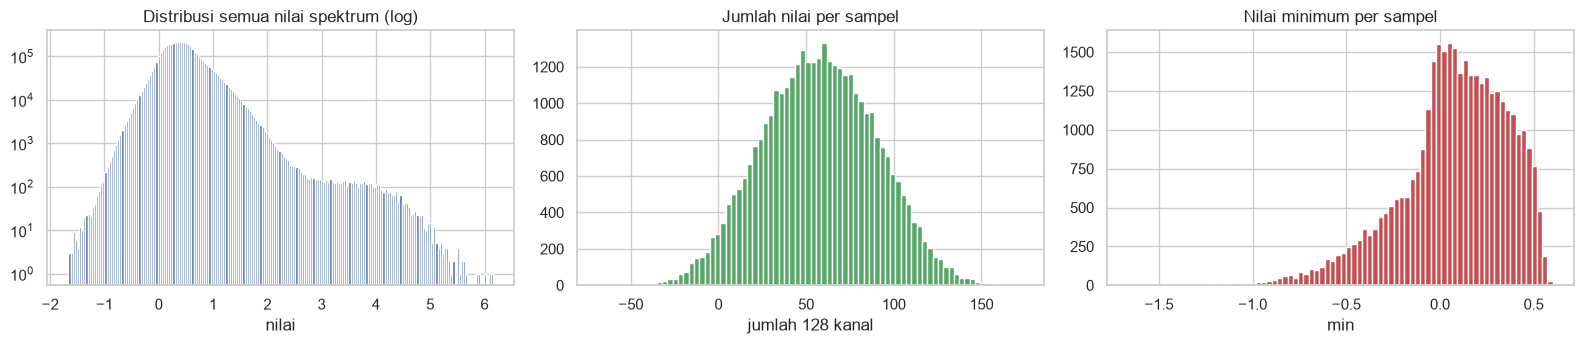

In [60]:
# ---- 4.1 Ukuran, tipe, rentang nilai, missing ----
n_nan, n_inf = int(np.isnan(X_RAW).sum()), int(np.isinf(X_RAW).sum())
sample_sum = X_RAW.sum(1)
summary = pd.Series({
    "bentuk": str(X_RAW.shape), "dtype asli": str(SPEC_RAW.dtype), "NaN": n_nan, "Inf": n_inf,
    "min": float(X_RAW.min()), "max": float(X_RAW.max()), "rata-rata": float(X_RAW.mean()), "std": float(X_RAW.std()),
    "% nilai negatif": float((X_RAW < 0).mean() * 100),
    "jumlah per sampel (p1 / median / p99)": np.percentile(sample_sum, [1, 50, 99]).round(1).tolist()})
print(summary.to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].hist(X_RAW.ravel(), bins=200, log=True, color="#4c72b0"); ax[0].set(title="Distribusi semua nilai spektrum (log)", xlabel="nilai")
ax[1].hist(sample_sum, bins=80, color="#55a868"); ax[1].set(title="Jumlah nilai per sampel", xlabel="jumlah 128 kanal")
ax[2].hist(X_RAW.min(1), bins=80, color="#c44e52"); ax[2].set(title="Nilai minimum per sampel", xlabel="min")
plt.tight_layout(); plt.show()

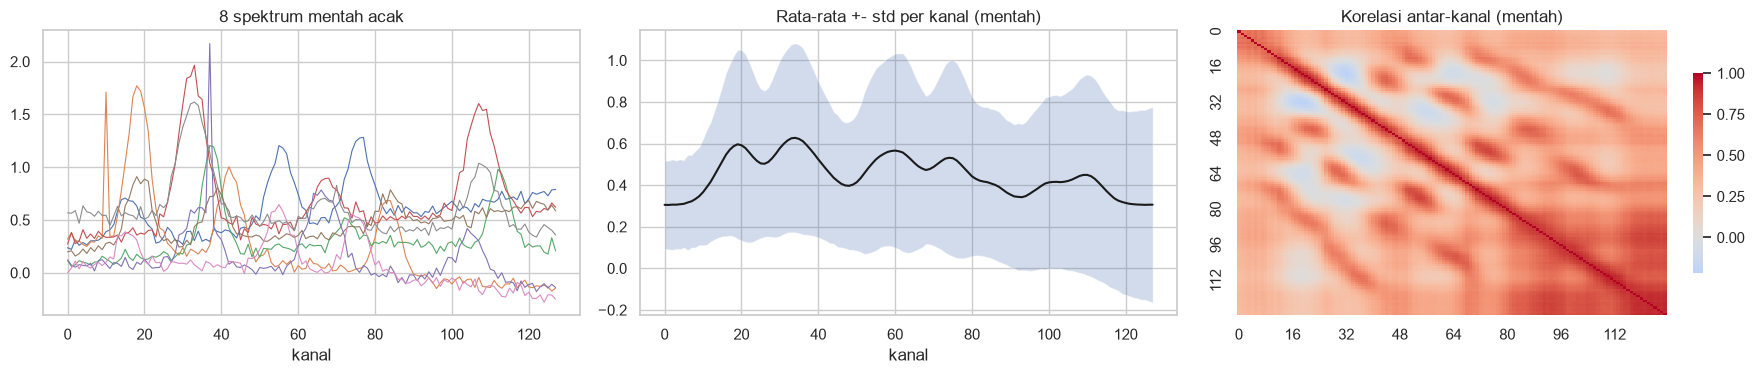

In [61]:
# ---- 4.2 Bentuk spektrum: contoh mentah, rata-rata, dan struktur korelasi antar-kanal ----
rng = np.random.default_rng(SEED); pick = rng.choice(N, 8, replace=False)
mu, sd = X_RAW.mean(0), X_RAW.std(0)
fig, ax = plt.subplots(1, 3, figsize=(18, 3.9))
for i in pick: ax[0].plot(X_RAW[i], lw=.8)
ax[0].set(title="8 spektrum mentah acak", xlabel="kanal")
ax[1].plot(mu, "k"); ax[1].fill_between(np.arange(L), mu - sd, mu + sd, alpha=.25); ax[1].set(title="Rata-rata +- std per kanal (mentah)", xlabel="kanal")
sns.heatmap(np.corrcoef(X_RAW[::4].T), cmap="coolwarm", center=0, ax=ax[2], cbar_kws={"shrink": .7}, xticklabels=16, yticklabels=16)
ax[2].set_title("Korelasi antar-kanal (mentah)")
plt.tight_layout(); plt.show()

**Interpretasi.** Spektrum bukan derau acak: terdapat **beberapa puncak sempit** pada posisi kanal tertentu, tetapi tiap sampel tampak "terangkat" pada level dasar yang berbeda-beda
(garis dasar yang melengkung, bahkan sebagian nilai negatif), ada **lonjakan tajam satu kanal**, dan puncak tampak **bergeser** antar-sampel. Rata-rata ± std per kanal sangat lebar karena campuran jenis material
dan distorsi ini, dan korelasi antar-kanal didominasi struktur pita-diagonal (kanal bertetangga berkorelasi) ditambah pengaruh baseline.

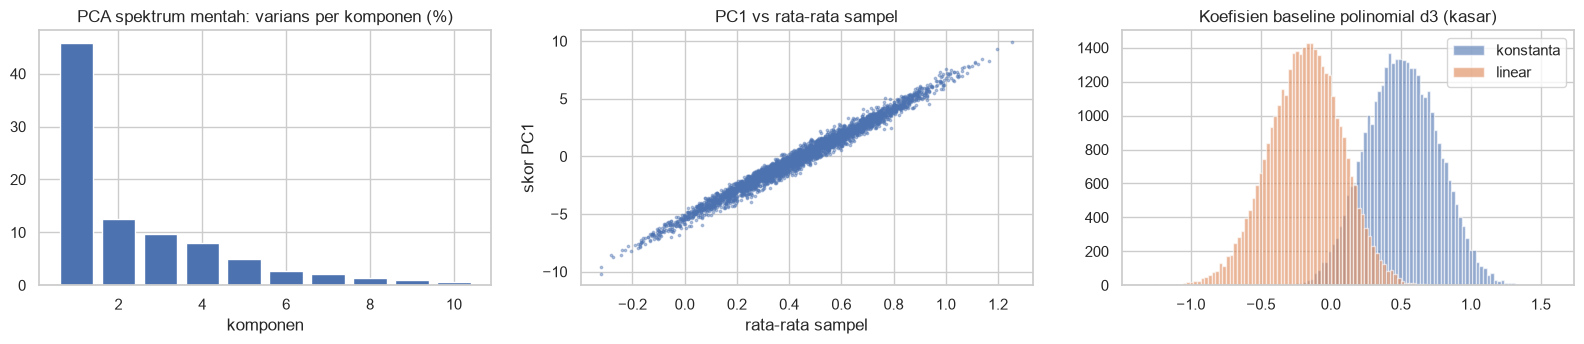

Varians PC1 = 45.9% | korelasi PC1 dengan rata-rata sampel = 0.991


In [62]:
# ---- 4.3 Baseline: apakah komponen terbesar variasi adalah jenis material atau offset? ----
pca_raw = PCA(10, random_state=SEED).fit(X_RAW); S_raw = pca_raw.transform(X_RAW)
t_ax = np.linspace(-1, 1, L); V3 = np.vander(t_ax, 4); coef = np.linalg.lstsq(V3, X_RAW.T.astype(np.float64), rcond=None)[0]   # polinomial d3 per sampel (kasar)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].bar(range(1, 11), pca_raw.explained_variance_ratio_ * 100); ax[0].set(title="PCA spektrum mentah: varians per komponen (%)", xlabel="komponen")
ax[1].scatter(X_RAW.mean(1)[::10], S_raw[::10, 0], s=3, alpha=.4); ax[1].set(title="PC1 vs rata-rata sampel", xlabel="rata-rata sampel", ylabel="skor PC1")
ax[2].hist(coef[3], bins=80, alpha=.6, label="konstanta"); ax[2].hist(coef[2], bins=80, alpha=.6, label="linear"); ax[2].legend(); ax[2].set_title("Koefisien baseline polinomial d3 (kasar)")
plt.tight_layout(); plt.show()
print(f"Varians PC1 = {pca_raw.explained_variance_ratio_[0] * 100:.1f}% | korelasi PC1 dengan rata-rata sampel = {np.corrcoef(S_raw[:, 0], X_RAW.mean(1))[0, 1]:.3f}")

**Interpretasi.** Komponen utama pertama menjelaskan hampir separuh varians **dan berkorelasi hampir sempurna dengan rata-rata sampel**: variasi terbesar pada data mentah adalah **offset/baseline** per sampel,
bukan perbedaan jenis material. Jika dibiarkan, algoritma clustering akan mengelompokkan berdasarkan tinggi baseline. Baseline harus dikoreksi per sampel sebelum representasi dipelajari.

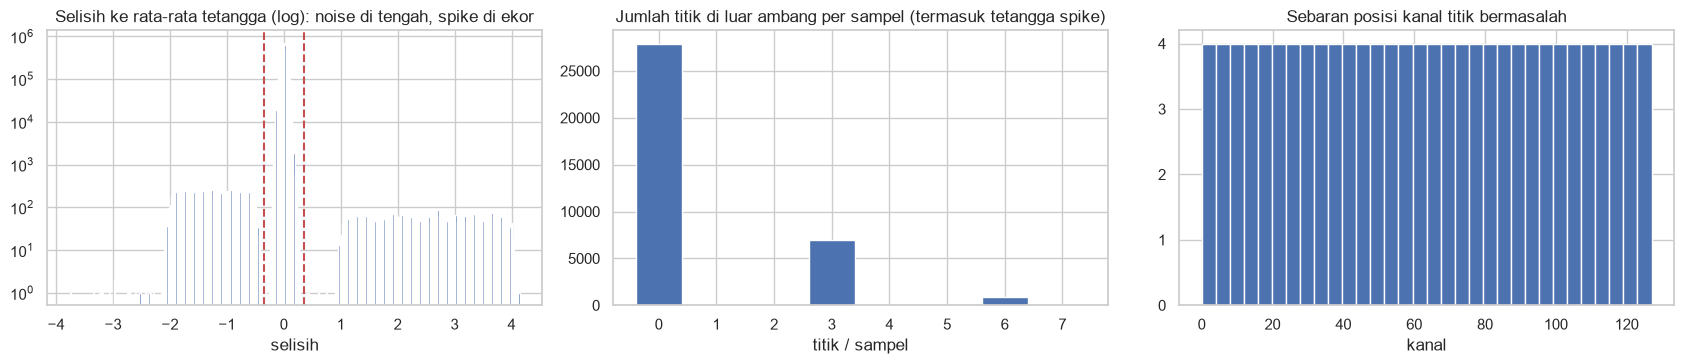

sigma noise (MAD) selisih = 0.0509 | ambang = 7.0 x MAD = 0.356 | sampel dengan >=1 titik di luar ambang = 22.5%
Histogram |selisih| per bin 0.05 (0..1): [3054764, 1233887, 205000, 14549, 587, 20, 1, 9, 36, 194, 396, 533, 586, 623, 608, 607, 616, 640, 637, 633]


In [63]:
# ---- 4.4 Spike: selisih tiap kanal terhadap rata-rata dua tetangganya ----
def neighbor_diff(X):
    d = np.zeros(X.shape, dtype=np.float64)
    d[:, 1:-1] = X[:, 1:-1] - 0.5 * (X[:, :-2] + X[:, 2:]); d[:, 0] = X[:, 0] - X[:, 1]; d[:, -1] = X[:, -1] - X[:, -2]
    return d

D_RAW = neighbor_diff(X_RAW); SIGMA_D = np.median(np.abs(D_RAW[:, 1:-1])) * 1.4826; THR_D = SPIKE_MAD * SIGMA_D
spike_eda = (np.abs(D_RAW) > THR_D)
per_sample = spike_eda.sum(1)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].hist(D_RAW[:, 1:-1].ravel(), bins=400, log=True); ax[0].axvline(THR_D, c="r", ls="--"); ax[0].axvline(-THR_D, c="r", ls="--")
ax[0].set(title="Selisih ke rata-rata tetangga (log): noise di tengah, spike di ekor", xlabel="selisih")
ax[1].bar(range(0, 8), np.bincount(np.minimum(per_sample, 7), minlength=8)); ax[1].set(title="Jumlah titik di luar ambang per sampel (termasuk tetangga spike)", xlabel="titik / sampel")
ax[2].hist(np.where(spike_eda.any(0), 1, 0).nonzero()[0], bins=L // 4); ax[2].set(title="Sebaran posisi kanal titik bermasalah", xlabel="kanal")
plt.tight_layout(); plt.show()
print(f"sigma noise (MAD) selisih = {SIGMA_D:.4f} | ambang = {SPIKE_MAD} x MAD = {THR_D:.3f} | sampel dengan >=1 titik di luar ambang = {spike_eda.any(1).mean() * 100:.1f}%")
a = np.abs(D_RAW[:, 1:-1]).ravel(); gap = np.histogram(a, bins=np.arange(0, 1.01, .05))[0]
print("Histogram |selisih| per bin 0.05 (0..1):", gap.tolist())

**Interpretasi.** Selisih ke tetangga memperlihatkan **dua populasi yang terpisah jelas**: puncak sempit di sekitar nol (noise) dan ekor lebar jauh di luar (spike), dengan **jurang hampir kosong** di antaranya. Ambang `7 × MAD` jatuh di jurang itu,
jadi pemisahan tidak sensitif terhadap pilihan angka persisnya. Sekitar **seperlima sampel** memuat minimal satu spike, berupa **lonjakan satu kanal yang nyaris selalu positif**, tersebar di seluruh kanal.
Selisih ke tetangga dipakai (bukan median-filter) karena **puncak spektrum yang sah juga sempit**; detektor yang terlalu agresif akan memotong puncak sebenarnya. Tetangga langsung sebuah spike ikut melewati ambang
(selisihnya setengah amplitudo spike), jadi deteksi hanya menandai **maksimum lokal** selisih.

NaN = 0, Inf = 0 -> tidak ada bacaan hilang pada spektrum (float16 mampu menyimpan NaN, jadi ini bukan artefak tipe data).


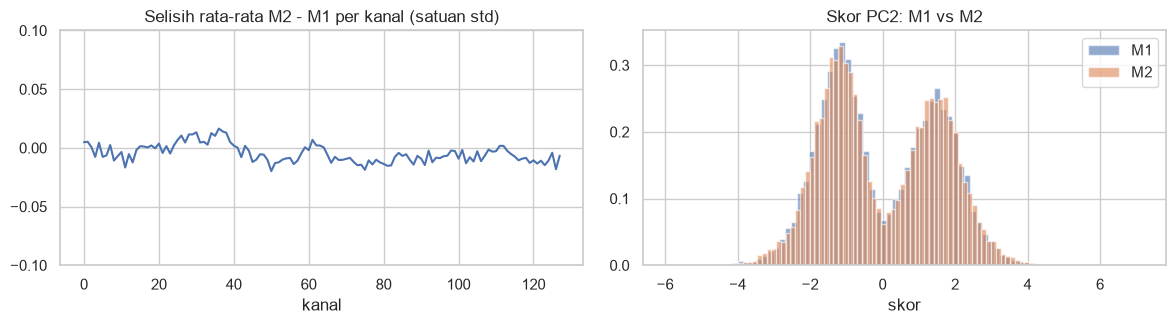

Selisih rata-rata M2-M1 terbesar = 0.0198 std | korelasi 5 PC pertama dengan mikroskop: [np.float64(0.004), np.float64(0.005), np.float64(0.004), np.float64(0.004), np.float64(0.006)]


In [64]:
# ---- 4.5 Missing values & efek mikroskop pada spektrum ----
print(f"NaN = {n_nan}, Inf = {n_inf} -> tidak ada bacaan hilang pada spektrum (float16 mampu menyimpan NaN, jadi ini bukan artefak tipe data).")
d_mic = (X_RAW[MIC == 1].mean(0) - X_RAW[MIC == 0].mean(0)) / X_RAW.std(0)
Z_pc = S_raw[:, :5]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(d_mic); ax[0].set(title="Selisih rata-rata M2 - M1 per kanal (satuan std)", xlabel="kanal"); ax[0].set_ylim(-0.1, 0.1)
for v, nm in [(0, "M1"), (1, "M2")]: ax[1].hist(S_raw[MIC == v, 1], bins=80, alpha=.6, label=nm, density=True)
ax[1].set(title="Skor PC2: M1 vs M2", xlabel="skor"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Selisih rata-rata M2-M1 terbesar = {np.abs(d_mic).max():.4f} std | korelasi 5 PC pertama dengan mikroskop: {[round(abs(np.corrcoef(Z_pc[:, i], MIC)[0, 1]), 3) for i in range(5)]}")

**Interpretasi.** **Tidak ada nilai hilang** pada spektrum, dan **mikroskop tidak memengaruhi spektrum** (selisih rata-rata M1 vs M2 nyaris nol, korelasi PC dengan mikroskop ≈ 0). Artinya perbedaan mikroskop adalah distorsi khusus **gambar**,
dan modality spektrum bisa dipakai sebagai jangkar yang bebas *domain shift* ketika digabung dengan gambar. Distorsi spektrum yang nyata adalah **baseline, spike, noise, dan geseran puncak** (geseran dikuantifikasi di 5.4).

# SECTION 5 — Preprocessing

## Bagian A — Image
Preprocessing dan embedding gambar dikerjakan **Anggota 1**; notebook ini tidak mengulanginya. Image embedding dimuat di Section 6 dalam format yang disepakati bersama.

## Bagian B — Spectrum
Urutan: **(1)** isi nilai hilang (tidak ada pada data ini, tetapi disiapkan) → **(2)** buang spike → **(3)** koreksi baseline → **(4)** normalisasi per sampel → **(5)** tensor untuk representation learning.

**Tanpa kebocoran:** semua langkah bekerja **per sampel** (tanpa label dan tanpa statistik global yang di-*fit*), sehingga tidak ada informasi dari sampel lain yang bocor ke sampel ini.
Clustering di notebook ini bersifat *transduktif* pada seluruh 36.000 sampel (semua sampel harus mendapat cluster), dan tidak ada label yang dipakai.

In [65]:
def fill_missing(X):
    # NaN/Inf -> interpolasi linear antar-kanal dalam satu sampel (tidak ada NaN di data ini; jaga-jaga)
    X = X.astype(np.float64).copy(); bad = ~np.isfinite(X); idx = np.arange(X.shape[1])
    for i in np.where(bad.any(1))[0]:
        m = bad[i]; X[i, m] = np.interp(idx[m], idx[~m], X[i, ~m])
    return X, int(bad.sum())

def despike(X, thr_mad=SPIKE_MAD, n_pass=2):
    # Spike = maksimum lokal dari |selisih ke rata-rata tetangga| di atas thr_mad x MAD. Diganti rata-rata kedua tetangganya.
    X = X.copy(); Lc = X.shape[1]; total = np.zeros(X.shape, dtype=bool)
    for _ in range(n_pass):
        d = neighbor_diff(X); thr = thr_mad * np.median(np.abs(d[:, 1:-1])) * 1.4826
        ad = np.abs(d); ap = np.pad(ad, ((0, 0), (1, 1)))
        sp = (ad > thr) & (ad >= ap[:, :-2]) & (ad >= ap[:, 2:])
        ii, jj = np.where(sp)
        if len(ii) == 0: break
        jl, jr = np.where(jj > 0, jj - 1, jj + 1), np.where(jj < Lc - 1, jj + 1, jj - 1)
        X[ii, jj] = 0.5 * (X[ii, jl] + X[ii, jr]); total |= sp
    return X, total

def remove_baseline(X, deg=BASE_DEG, iters=BASE_ITERS):
    # Baseline polinomial dengan pemotongan iteratif (gaya ModPoly): nilai di atas kurva dipotong ke kurva,
    # sehingga puncak tidak menarik baseline ke atas. Operasi linear -> vektor untuk semua sampel sekaligus.
    Lc = X.shape[1]; V = np.vander(np.linspace(-1, 1, Lc), deg + 1); H = V @ np.linalg.pinv(V)
    y = X.T.copy()
    for _ in range(iters):
        y = np.minimum(X.T, H @ y)
    return X - y.T, y.T

def zscore_rows(X):
    return (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)

def preprocess_spectra(X):
    X_fill, n_fill = fill_missing(X)
    X_desp, spk = despike(X_fill)
    X_base, base = remove_baseline(X_desp)
    return {"fill": X_fill, "despike": X_desp, "spike_mask": spk, "baseline": base, "corrected": X_base,
            "final": zscore_rows(X_base).astype(np.float32), "n_filled": n_fill}

PP = preprocess_spectra(X_RAW)
X_PP = PP["final"]
print(f"Nilai hilang diisi: {PP['n_filled']} | spike dibuang: {int(PP['spike_mask'].sum())} pada {PP['spike_mask'].any(1).mean() * 100:.1f}% sampel "
      f"(maks {int(PP['spike_mask'].sum(1).max())} per sampel)")
d_after = neighbor_diff(PP["despike"]); print(f"Titik di luar ambang setelah despike: {int((np.abs(d_after) > THR_D).sum())} dari {d_after.size} (sebelum: {int(spike_eda.sum())})")
print(f"Setelah normalisasi: rata-rata baris = {X_PP.mean(1).mean():+.4f}, std baris = {X_PP.std(1).mean():.4f} | NaN = {int(np.isnan(X_PP).sum())}")
np.save(OUTPUT_DIR / "spektrum_bersih.npy", X_PP)

Nilai hilang diisi: 0 | spike dibuang: 9337 pada 22.5% sampel (maks 6 per sampel)
Titik di luar ambang setelah despike: 143 dari 4608000 (sebelum: 27477)
Setelah normalisasi: rata-rata baris = -0.0000, std baris = 1.0000 | NaN = 0


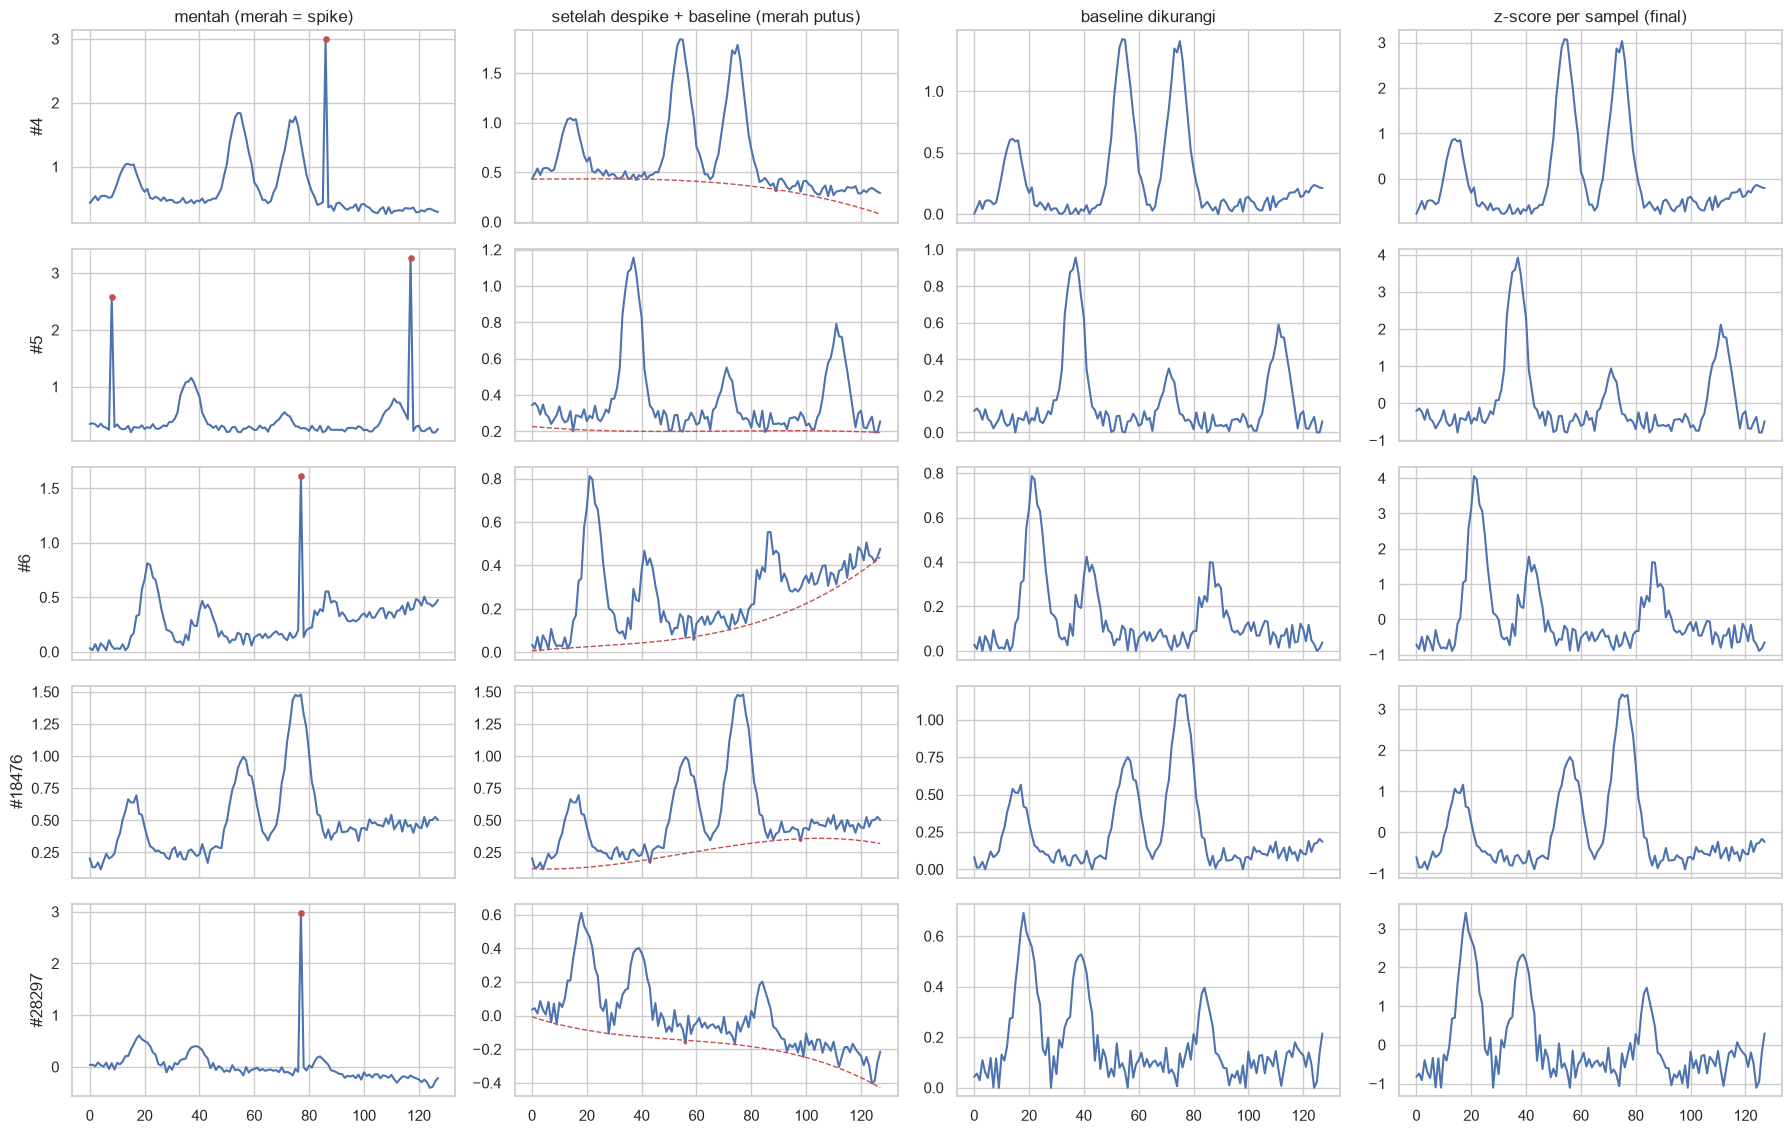

In [66]:
# ---- 5.1 Visualisasi tiap langkah pada beberapa sampel ----
sel = np.where(PP["spike_mask"].any(1))[0][:3].tolist() + rng.choice(N, 2, replace=False).tolist()
fig, ax = plt.subplots(len(sel), 4, figsize=(18, 2.3 * len(sel)), sharex=True)
for r, i in enumerate(sel):
    ax[r, 0].plot(X_RAW[i]); ax[r, 1].plot(PP["despike"][i]); ax[r, 1].plot(PP["baseline"][i], "r--", lw=1)
    ax[r, 2].plot(PP["corrected"][i]); ax[r, 3].plot(X_PP[i])
    sp = np.where(PP["spike_mask"][i])[0]; ax[r, 0].scatter(sp, X_RAW[i, sp], c="r", s=14, zorder=3)
    ax[r, 0].set_ylabel(f"#{i}")
for c, tt in enumerate(["mentah (merah = spike)", "setelah despike + baseline (merah putus)", "baseline dikurangi", "z-score per sampel (final)"]): ax[0, c].set_title(tt)
plt.tight_layout(); plt.show()

In [67]:
# ---- 5.2 Kontribusi tiap langkah, diukur TANPA label: kualitas pemisahan cluster (silhouette terbaik untuk k=2..8) ----
def prep_for_cluster(E, n=16):
    E = np.asarray(E, dtype=np.float64); return PCA(min(n, E.shape[1]), random_state=SEED).fit_transform(E - E.mean(0))

def cluster_quality(E, ks=range(2, 9), n_sample=8000):
    Z = prep_for_cluster(E); sub = np.random.default_rng(SEED).choice(len(Z), min(n_sample, len(Z)), replace=False); rows = []
    for k in ks:
        lab = KMeans(k, n_init=3, random_state=SEED).fit_predict(Z[sub])
        rows.append((k, silhouette_score(Z[sub], lab), davies_bouldin_score(Z[sub], lab), calinski_harabasz_score(Z[sub], lab)))
    return pd.DataFrame(rows, columns=["k", "silhouette", "DB", "CH"])

variants = {"z-score saja (tanpa pembersihan)": zscore_rows(PP["fill"]),
            "+ despike": zscore_rows(PP["despike"]),
            "+ baseline (tanpa despike)": zscore_rows(remove_baseline(PP["fill"])[0]),
            "+ despike + baseline (final)": X_PP}
rows = []
for nm, F_ in variants.items():
    q = cluster_quality(F_); b = q.loc[q["silhouette"].idxmax()]; rows.append({"langkah": nm, "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"]})
tab_pp = pd.DataFrame(rows); print(tab_pp.round(3).to_string(index=False))
N_SPEC_GROUPS = int(tab_pp.iloc[-1]["pada k"]); print(f"\nJumlah kelompok spektral yang terbaik setelah pembersihan (k dengan silhouette tertinggi): {N_SPEC_GROUPS}")

                         langkah  silhouette terbaik  pada k  DB di k itu
z-score saja (tanpa pembersihan)               0.339       4        1.229
                       + despike               0.359       4        1.184
      + baseline (tanpa despike)               0.448       4        0.929
    + despike + baseline (final)               0.483       4        0.866

Jumlah kelompok spektral yang terbaik setelah pembersihan (k dengan silhouette tertinggi): 4


**Interpretasi.** Tiap langkah pembersihan menaikkan keterpisahan cluster yang terukur **tanpa label apa pun**, dan kombinasi despike + baseline memberi hasil terbaik. Hasil akhir juga menunjukkan bahwa spektrum
bersih membentuk **sejumlah kecil kelompok spektral yang jelas** (kolom "pada k"). Perlu dicatat bahwa k dengan silhouette tertinggi pada **spektrum saja** belum tentu jumlah jenis material sebenarnya:
dua jenis material dapat berbagi pola spektrum yang sama dan hanya dibedakan oleh gambar (dianalisis di Section 8–11).

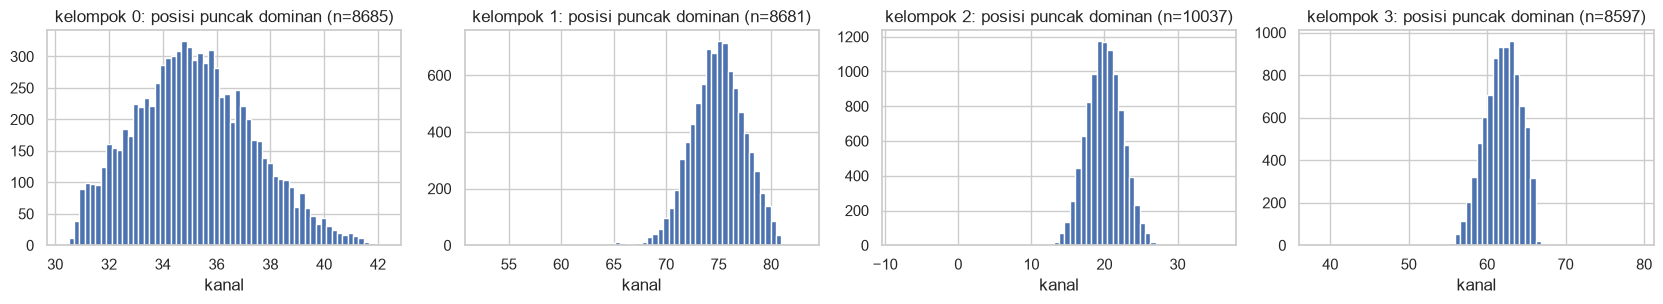

Std geseran puncak per kelompok (kanal): [2.19, 2.61, 2.46, 2.39] | persentil 1/99 geseran: [-5.5, 5.2]


In [68]:
# ---- 5.3 Posisi puncak setelah pembersihan: apakah geseran puncak kontinu (distorsi) atau terpisah jadi beberapa mode? ----
def estimate_peak_shift(X, n_groups):
    Z = PCA(12, random_state=SEED).fit_transform(X); g = KMeans(n_groups, n_init=5, random_state=SEED).fit_predict(Z)
    S = gaussian_filter1d(X, 2.0, axis=1, mode="nearest"); shift = np.zeros(len(X)); pos_all = np.zeros(len(X)); Lc = X.shape[1]
    for c in range(n_groups):
        m = np.where(g == c)[0]; Sg = S[m]; modal = np.bincount(Sg.argmax(1)).argmax()
        lo, hi = max(modal - 12, 1), min(modal + 12, Lc - 2); a = Sg[:, lo:hi].argmax(1) + lo; r = np.arange(len(a))
        y0, y1, y2 = Sg[r, a - 1], Sg[r, a], Sg[r, a + 1]; pos = a + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2 + 1e-9)
        shift[m] = pos - np.median(pos); pos_all[m] = pos
    return shift, g, pos_all

SHIFT, G_SPEC, POS_PEAK = estimate_peak_shift(X_PP, N_SPEC_GROUPS)
fig, ax = plt.subplots(1, N_SPEC_GROUPS, figsize=(4.2 * N_SPEC_GROUPS, 3.2))
for c in range(N_SPEC_GROUPS):
    ax[c].hist(POS_PEAK[G_SPEC == c], bins=60, color="#4c72b0"); ax[c].set_title(f"kelompok {c}: posisi puncak dominan (n={int((G_SPEC == c).sum())})"); ax[c].set_xlabel("kanal")
plt.tight_layout(); plt.show()
print("Std geseran puncak per kelompok (kanal):", [round(float(SHIFT[G_SPEC == c].std()), 2) for c in range(N_SPEC_GROUPS)],
      "| persentil 1/99 geseran:", np.percentile(SHIFT, [1, 99]).round(1).tolist())

**Interpretasi.** Di dalam tiap kelompok spektral, posisi puncak dominan menyebar **kontinu dan satu-puncak (unimodal)** dengan simpangan baku sekitar 2 kanal dan rentang kira-kira ±5 kanal. Ini adalah **distorsi geseran** (sesuai ketentuan UTS), bukan
penanda kelas yang terpisah. Dua implikasi: **(1)** KMeans pada spektrum mentah akan cenderung **memecah satu jenis material menjadi dua** hanya karena geseran (itulah sebabnya jumlah cluster yang dipilih harus diuji dengan banyak kriteria, Section 11);
**(2)** representasi spektrum harus **tahan terhadap geseran ±5 kanal** tetapi tetap membedakan kelompok yang puncaknya berjarak puluhan kanal. Inilah dasar augmentasi pada Section 7.
`SHIFT` (geseran per sampel) hanya dipakai sebagai **diagnostik** untuk mengukur seberapa jauh sebuah embedding masih "menyimpan" geseran; ia tidak dipakai untuk melatih apa pun.

In [69]:
# ---- 5.4 Persiapan tensor ----
X_T = torch.from_numpy(X_PP[:, None, :]).to(DEVICE)       # (N, 1, 128) float32, seluruhnya di GPU (+-18 MB)
print("Tensor spektrum:", tuple(X_T.shape), X_T.dtype, X_T.device, "| urutan baris = urutan meta (IDS[i] <-> X_T[i])")
assert X_T.shape == (N, 1, L) and len(IDS) == N

Tensor spektrum: (36000, 1, 128) torch.float32 cpu | urutan baris = urutan meta (IDS[i] <-> X_T[i])


## Bagian A — Preprocessing gambar mikroskopis (Anggota 1)

Gambar dinormalisasi per sampel tanpa menggunakan label material. Bagian preprocessing spektrum tetap berada di atas dan tidak ditimpa.

Preprocessing gambar: (36000, 64, 64) float32 | mean/std global: -0.0001 0.9994


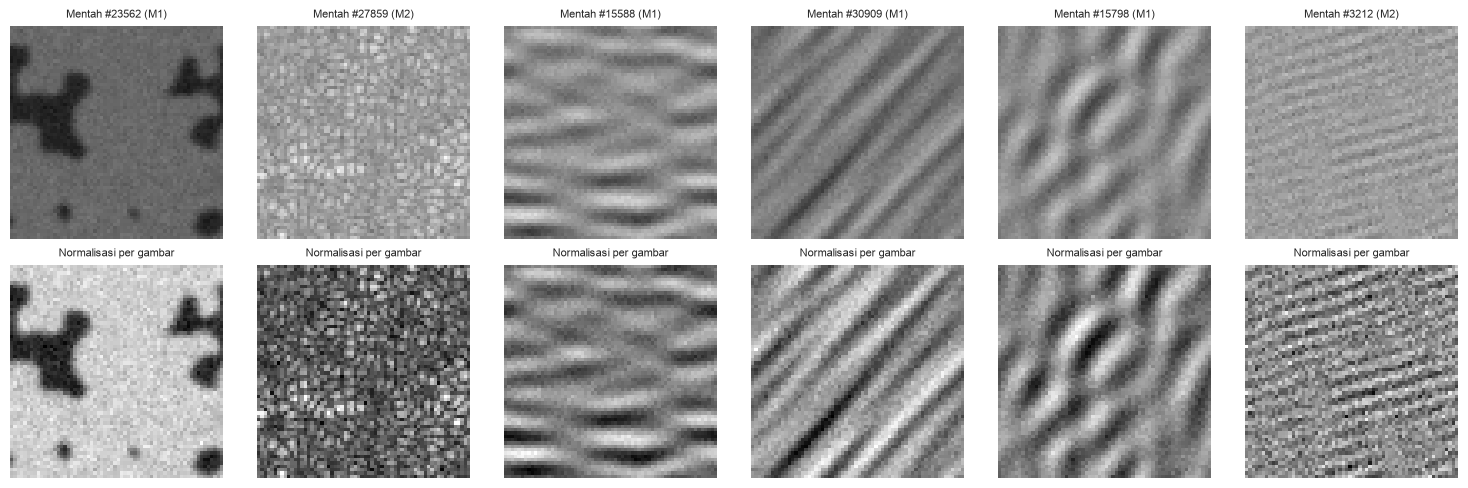

Statistik setelah preprocessing:
              mean     std
mikroskop                
M1        -0.0002  0.9991
M2        -0.0001  0.9997
NMI KMeans PCA setelah preprocessing vs mikroskop: 0.0


In [70]:
# ---- 5.A Preprocessing gambar mikroskopis (Anggota 1) ----
if HAS_IMAGES:
    def preprocess_images_per_sample(images_uint8):
        """Skala [0,1], standardisasi per gambar, lalu clipping [-4,4]."""
        x = images_uint8.astype(np.float32) / 255.0
        mean = x.mean(axis=(1, 2), keepdims=True)
        std = x.std(axis=(1, 2), keepdims=True)
        return np.clip((x - mean) / (std + 1e-6), -4, 4).astype(np.float32)

    XP_IMAGE = preprocess_images_per_sample(GAMBAR)  # (N,64,64), float32
    assert XP_IMAGE.shape == GAMBAR.shape and np.isfinite(XP_IMAGE).all()
    print("Preprocessing gambar:", XP_IMAGE.shape, XP_IMAGE.dtype,
          "| mean/std global:", round(float(XP_IMAGE.mean()), 4), round(float(XP_IMAGE.std()), 4))

    # Visualisasi sebelum-sesudah
    rng_pre = np.random.default_rng(SEED)
    fig, ax = plt.subplots(2, 6, figsize=(15, 5))
    for j, idx in enumerate(rng_pre.choice(N, 6, replace=False)):
        ax[0,j].imshow(GAMBAR[idx], cmap="gray", vmin=0, vmax=255)
        ax[0,j].set_title(f"Mentah #{idx} ({'M2' if MIC[idx] else 'M1'})", fontsize=8)
        ax[1,j].imshow(XP_IMAGE[idx], cmap="gray")
        ax[1,j].set_title("Normalisasi per gambar", fontsize=8)
        ax[0,j].axis("off"); ax[1,j].axis("off")
    plt.tight_layout(); plt.show()

    IMG_PP_STATS = pd.DataFrame({"mean": XP_IMAGE.mean((1,2)), "std": XP_IMAGE.std((1,2)),
                                 "mikroskop": np.where(MIC == 1, "M2", "M1")})
    print("Statistik setelah preprocessing:\n", IMG_PP_STATS.groupby("mikroskop")[["mean", "std"]].mean().round(4))
    IMG_PP_PCA = PCA(n_components=min(10, N, XP_IMAGE.shape[1]*XP_IMAGE.shape[2]), random_state=SEED)
    IMG_PP_SCORE = IMG_PP_PCA.fit_transform(XP_IMAGE.reshape(N, -1)[IMG_SUB])
    IMG_PP_KM = KMeans(4, n_init=5, random_state=SEED).fit_predict(StandardScaler().fit_transform(IMG_PP_SCORE))
    print("NMI KMeans PCA setelah preprocessing vs mikroskop:",
          round(normalized_mutual_info_score(IMG_PP_KM, MIC[IMG_SUB]), 3))
    XT_IMAGE = torch.from_numpy(XP_IMAGE[:, None, :, :])  # CPU tensor; batch dipindah ke DEVICE saat training
else:
    XP_IMAGE, XT_IMAGE = None, None


# SECTION 6 — Image Representation Learning, Evaluasi & Embedding (Anggota 1)

Bagian ini menjalankan representasi citra secara langsung di notebook gabungan: PCA sebagai baseline, convolutional Autoencoder, dan Contrastive Learning (NT-Xent). Embedding terpilih disimpan sebagai `embedding_gambar.npz` sekaligus disiapkan pada variabel `E_IMG` untuk Section 8 (fusion). Parameter gambar memakai awalan `IMG_` agar tidak menimpa konfigurasi spektrum.

In [71]:
# ---- 6.1 Konfigurasi khusus gambar (tidak menimpa konfigurasi spektrum) ----
if HAS_IMAGES:
    IMG_EMB_DIM = 32
    IMG_BATCH = 256
    IMG_LR = 1e-3
    IMG_TAU = 0.2
    IMG_EPOCHS_CL = 12
    IMG_EPOCHS_AE = 8
    IMG_RETRAIN = RETRAIN
    IMG_ROT_MAX_DEG = 180
    IMG_SCALE_RANGE = (0.8, 1.25)
    IMG_SHIFT_FRAC = 0.08
    IMG_OUT_EMB_FILE = "embedding_gambar.npz"
    IMG_OUTPUT_DIR = OUTPUT_DIR / "image_models"
    IMG_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    assert XP_IMAGE is not None and len(XP_IMAGE) == N

    class ImgConvBlock(nn.Sequential):
        def __init__(self, in_ch, out_ch):
            super().__init__(nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
                             nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.MaxPool2d(2))

    class ImgEncoder(nn.Module):
        def __init__(self, emb_dim=IMG_EMB_DIM, channels=(16, 32, 64, 128)):
            super().__init__()
            layers, in_ch = [], 1
            for out_ch in channels:
                layers.append(ImgConvBlock(in_ch, out_ch)); in_ch = out_ch
            self.conv = nn.Sequential(*layers)
            self.fc = nn.Linear(channels[-1], emb_dim)
        def forward(self, x):
            return self.fc(self.conv(x).mean((2, 3)))

    class ImgContrastiveModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.enc = ImgEncoder()
            self.head = nn.Sequential(nn.Linear(IMG_EMB_DIM, 64), nn.ReLU(inplace=True), nn.Linear(64, 32))
        def forward(self, x):
            return F.normalize(self.head(self.enc(x)), dim=1)

    class ImgConvAE(nn.Module):
        def __init__(self):
            super().__init__()
            self.enc = ImgEncoder()
            self.fc = nn.Linear(IMG_EMB_DIM, 128 * 4 * 4)
            def up(in_ch, out_ch):
                return nn.Sequential(nn.ConvTranspose2d(in_ch, out_ch, 4, 2, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
            self.dec = nn.Sequential(up(128, 96), up(96, 48), up(48, 24), up(24, 12), nn.Conv2d(12, 1, 3, padding=1))
        def forward(self, x):
            z = self.enc(x)
            return self.dec(F.relu(self.fc(z)).view(-1, 128, 4, 4)), z

    def img_augment(x, rot=IMG_ROT_MAX_DEG, scale=IMG_SCALE_RANGE, shift=IMG_SHIFT_FRAC):
        batch, _, height, width = x.shape
        dev = x.device
        angle = (torch.rand(batch, device=dev) * 2 - 1) * np.deg2rad(rot)
        sc = torch.empty(batch, device=dev).uniform_(*scale)
        flip = (torch.rand(batch, device=dev) < 0.5).float() * 2 - 1
        theta = torch.zeros(batch, 2, 3, device=dev)
        theta[:,0,0] = torch.cos(angle) / sc * flip
        theta[:,0,1] = -torch.sin(angle) / sc
        theta[:,1,0] = torch.sin(angle) / sc * flip
        theta[:,1,1] = torch.cos(angle) / sc
        theta[:,:,2] = (torch.rand(batch, 2, device=dev) * 2 - 1) * shift * 2
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        y = F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)
        y = y * torch.empty(batch,1,1,1,device=dev).uniform_(0.7,1.4) + torch.empty(batch,1,1,1,device=dev).uniform_(-0.5,0.5)
        y = y + 0.1 * torch.randn_like(y)
        return (y - y.mean((1,2,3), keepdim=True)) / (y.std((1,2,3), keepdim=True) + 1e-6)

    def img_nt_xent(z1, z2, tau=IMG_TAU):
        z = torch.cat([z1, z2], dim=0); batch = z1.shape[0]
        sim = z @ z.T / tau
        sim.fill_diagonal_(-1e9)
        target = torch.cat([torch.arange(batch, 2*batch), torch.arange(0, batch)]).to(z.device)
        return F.cross_entropy(sim, target)

    @torch.no_grad()
    def img_embed(encoder, batch_size=512):
        encoder.eval(); out=[]
        for start in range(0, N, batch_size):
            xb = XT_IMAGE[start:start+batch_size].to(DEVICE)
            out.append(encoder(xb).float().cpu().numpy())
        return np.concatenate(out, axis=0).astype(np.float32)

    def img_fit_or_load(name, model, train_fn):
        path = IMG_OUTPUT_DIR / f"{name}.pt"
        model = model.to(DEVICE)
        if path.exists() and not IMG_RETRAIN:
            checkpoint = torch.load(path, map_location=DEVICE)
            model.load_state_dict(checkpoint["state"])
            print(f"[cache gambar] {name} dimuat dari {path}")
            return model, checkpoint["history"]
        history = train_fn(model)
        torch.save({"state": model.state_dict(), "history": history}, path)
        return model, history

    def img_train_contrastive(model):
        model.train(); opt = torch.optim.AdamW(model.parameters(), lr=IMG_LR, weight_decay=1e-4)
        batches = int(np.ceil(N / IMG_BATCH)); total_steps = IMG_EPOCHS_CL * batches
        scheduler = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=IMG_LR*3, total_steps=total_steps)
        history=[]; t0=time.time()
        for epoch in range(IMG_EPOCHS_CL):
            perm = torch.randperm(N); total=0.0
            for start in range(0, N, IMG_BATCH):
                idx = perm[start:start+IMG_BATCH]
                xb = XT_IMAGE[idx].to(DEVICE)
                loss = img_nt_xent(model(img_augment(xb)), model(img_augment(xb)))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); scheduler.step()
                total += float(loss.item())
            avg = total / batches; history.append(avg)
            print(f"[gambar contrastive] epoch {epoch+1}/{IMG_EPOCHS_CL} | NT-Xent={avg:.5f} | {time.time()-t0:.0f}s")
        return history

    def img_train_autoencoder(model):
        model.train(); opt = torch.optim.AdamW(model.parameters(), lr=IMG_LR, weight_decay=1e-4)
        batches = int(np.ceil(N / IMG_BATCH)); total_steps = IMG_EPOCHS_AE * batches
        scheduler = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=IMG_LR*3, total_steps=total_steps)
        history=[]; t0=time.time()
        for epoch in range(IMG_EPOCHS_AE):
            perm = torch.randperm(N); total=0.0
            for start in range(0, N, IMG_BATCH):
                idx = perm[start:start+IMG_BATCH]
                xb = XT_IMAGE[idx].to(DEVICE)
                recon, _ = model(xb)
                loss = F.mse_loss(recon, xb)
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); scheduler.step()
                total += float(loss.item())
            avg = total / batches; history.append(avg)
            print(f"[gambar autoencoder] epoch {epoch+1}/{IMG_EPOCHS_AE} | MSE={avg:.6f} | {time.time()-t0:.0f}s")
        return history
else:
    print("Tidak ada citra; representation learning gambar dilewati.")


[gambar contrastive] epoch 1/12 | NT-Xent=4.34885 | 134s
[gambar contrastive] epoch 2/12 | NT-Xent=3.30292 | 275s
[gambar contrastive] epoch 3/12 | NT-Xent=2.99088 | 527s
[gambar contrastive] epoch 4/12 | NT-Xent=2.85030 | 653s
[gambar contrastive] epoch 5/12 | NT-Xent=2.73953 | 781s
[gambar contrastive] epoch 6/12 | NT-Xent=2.67055 | 908s
[gambar contrastive] epoch 7/12 | NT-Xent=2.62810 | 1033s
[gambar contrastive] epoch 8/12 | NT-Xent=2.57811 | 1155s
[gambar contrastive] epoch 9/12 | NT-Xent=2.54365 | 1281s
[gambar contrastive] epoch 10/12 | NT-Xent=2.51704 | 1409s
[gambar contrastive] epoch 11/12 | NT-Xent=2.50244 | 1544s
[gambar contrastive] epoch 12/12 | NT-Xent=2.49004 | 1669s
[gambar autoencoder] epoch 1/8 | MSE=1.007136 | 113s
[gambar autoencoder] epoch 2/8 | MSE=0.990206 | 225s
[gambar autoencoder] epoch 3/8 | MSE=0.959365 | 334s
[gambar autoencoder] epoch 4/8 | MSE=0.934454 | 456s
[gambar autoencoder] epoch 5/8 | MSE=0.912540 | 575s
[gambar autoencoder] epoch 6/8 | MSE=0.896

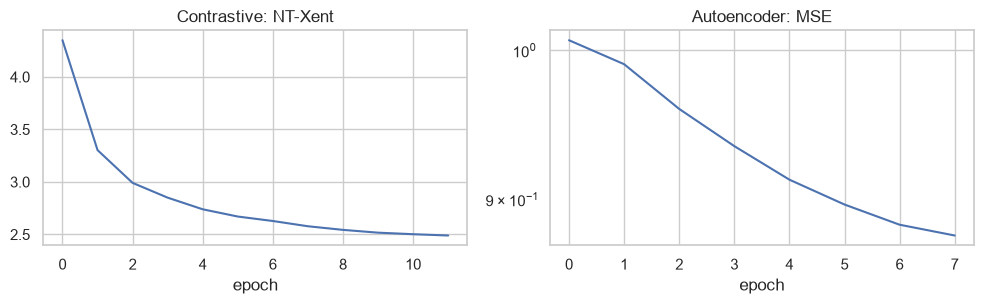

PCA          shape=(36000, 32) finite=True
Autoencoder  shape=(36000, 32) finite=True
Contrastive  shape=(36000, 32) finite=True

Evaluasi representasi gambar (tanpa label material):
              silhouette  k_terbaik  kebocoran_mikroskop_bal_acc  invariansi
metode                                                                     
PCA               0.148          2                        0.505       0.040
Autoencoder       0.346          2                        0.507       0.221
Contrastive       0.363          8                        0.892       0.641

Peringkat agregat:
              silhouette  leakage  invariance  rata_rata
metode                                                 
PCA                 3.0      1.0         3.0       2.33
Autoencoder         2.0      2.0         2.0       2.00
Contrastive         1.0      3.0         1.0       1.67
Representasi gambar terpilih: Contrastive


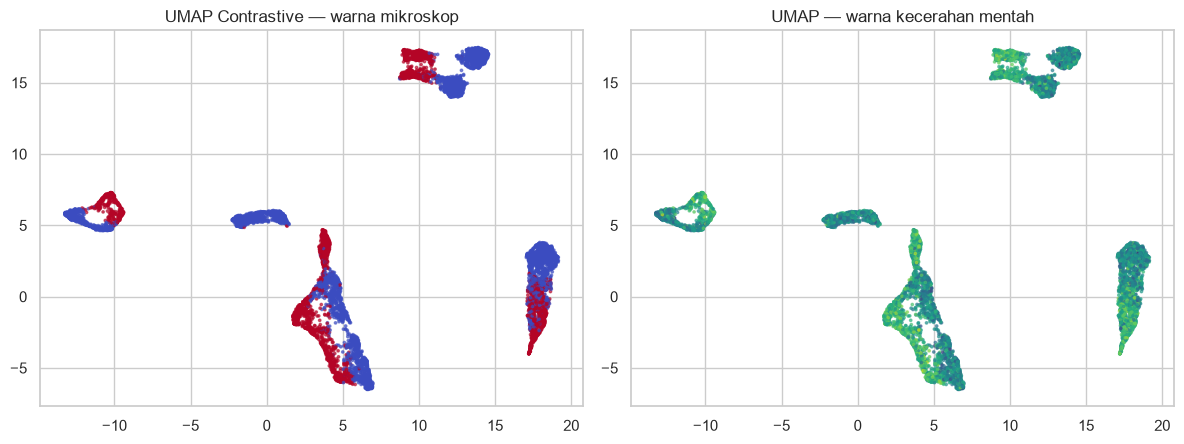

OK: embedding gambar tersimpan di C:\Users\Echa\Documents\UTS_DL_Clustering\kode\outputs\embedding_gambar.npz | shape=(36000, 32) | pilihan=Contrastive
MODE = multimodal


In [72]:
# ---- 6.2 Training model gambar, evaluasi tanpa label, dan pemilihan representasi ----
if HAS_IMAGES:
    set_seed(); IMG_CL_MODEL, IMG_HIST_CL = img_fit_or_load("img_contrastive", ImgContrastiveModel(), img_train_contrastive)
    set_seed(); IMG_AE_MODEL, IMG_HIST_AE = img_fit_or_load("img_autoencoder", ImgConvAE(), img_train_autoencoder)

    IMG_EMBEDDINGS = {
        "PCA": PCA(n_components=IMG_EMB_DIM, random_state=SEED).fit_transform(XP_IMAGE.reshape(N, -1)).astype(np.float32),
        "Autoencoder": img_embed(IMG_AE_MODEL.enc),
        "Contrastive": img_embed(IMG_CL_MODEL.enc)
    }
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(IMG_HIST_CL); ax[0].set(title="Contrastive: NT-Xent", xlabel="epoch")
    ax[1].plot(IMG_HIST_AE); ax[1].set(title="Autoencoder: MSE", xlabel="epoch", yscale="log")
    plt.tight_layout(); plt.show()
    for name, emb in IMG_EMBEDDINGS.items():
        print(f"{name:12s} shape={emb.shape} finite={np.isfinite(emb).all()}")
        assert emb.shape == (N, IMG_EMB_DIM) and np.isfinite(emb).all()

    IMG_SUB_EVAL = np.random.default_rng(SEED).choice(N, min(8000, N), replace=False)
    def img_best_silhouette(E):
        z = PCA(min(16, E.shape[1]), random_state=SEED).fit_transform(StandardScaler().fit_transform(E[IMG_SUB_EVAL]))
        best = (-1.0, None)
        for k in range(2, 9):
            labels = KMeans(k, n_init=5, random_state=SEED).fit_predict(z)
            score = silhouette_score(z, labels, sample_size=min(4000, len(z)), random_state=SEED)
            if score > best[0]: best = (score, k)
        return best
    def img_mic_leakage(E):
        z = StandardScaler().fit_transform(E[IMG_SUB_EVAL])
        return cross_val_score(LogisticRegression(max_iter=500, class_weight="balanced"), z, MIC[IMG_SUB_EVAL], cv=5, scoring="balanced_accuracy").mean()
    @torch.no_grad()
    def img_invariance(encoder):
        encoder.eval(); x = XT_IMAGE[IMG_SUB_EVAL[:min(1500, len(IMG_SUB_EVAL))]].to(DEVICE); set_seed()
        a = F.normalize(encoder(x), dim=1); b = F.normalize(encoder(img_augment(x)), dim=1)
        return float(((a*b).sum(1) - (a*b.roll(1,0)).sum(1)).mean().item())
    def img_pca_invariance():
        sub = IMG_SUB_EVAL[:min(1500, len(IMG_SUB_EVAL))]
        p = PCA(n_components=IMG_EMB_DIM, random_state=SEED).fit(XP_IMAGE.reshape(N,-1)[IMG_SUB_EVAL])
        x = XT_IMAGE[sub]; set_seed()
        xa = x.reshape(len(x),-1).numpy()
        xb = img_augment(x.to(DEVICE)).cpu().reshape(len(x),-1).numpy()
        a = F.normalize(torch.from_numpy(p.transform(xa)), dim=1)
        b = F.normalize(torch.from_numpy(p.transform(xb)), dim=1)
        return float(((a*b).sum(1) - (a*b.roll(1,0)).sum(1)).mean().item())

    IMG_INV = {"PCA": img_pca_invariance(), "Autoencoder": img_invariance(IMG_AE_MODEL.enc), "Contrastive": img_invariance(IMG_CL_MODEL.enc)}
    img_rows=[]
    for name, emb in IMG_EMBEDDINGS.items():
        sil, best_k = img_best_silhouette(emb)
        img_rows.append({"metode":name, "silhouette":sil, "k_terbaik":best_k,
                         "kebocoran_mikroskop_bal_acc":img_mic_leakage(emb), "invariansi":IMG_INV[name]})
    IMG_EVAL = pd.DataFrame(img_rows).set_index("metode")
    print("\nEvaluasi representasi gambar (tanpa label material):\n", IMG_EVAL.round(3))
    ranks = pd.DataFrame({"silhouette":IMG_EVAL["silhouette"].rank(ascending=False),
                          "leakage":IMG_EVAL["kebocoran_mikroskop_bal_acc"].rank(ascending=True),
                          "invariance":IMG_EVAL["invariansi"].rank(ascending=False)})
    print("\nPeringkat agregat:\n", ranks.assign(rata_rata=ranks.mean(1)).round(2))
    IMG_CHOICE = ranks.mean(1).idxmin()
    print("Representasi gambar terpilih:", IMG_CHOICE)

    # Visualisasi UMAP embedding terpilih, warna menunjukkan mikroskop (diagnostik domain shift)
    try:
        img_umap = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(
            StandardScaler().fit_transform(IMG_EMBEDDINGS[IMG_CHOICE][IMG_SUB_EVAL]))
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
        ax[0].scatter(img_umap[:,0], img_umap[:,1], c=MIC[IMG_SUB_EVAL], cmap="coolwarm", s=3, alpha=.6)
        ax[0].set_title(f"UMAP {IMG_CHOICE} — warna mikroskop")
        ax[1].scatter(img_umap[:,0], img_umap[:,1], c=img_mean[IMG_SUB_EVAL], cmap="viridis", s=3, alpha=.6)
        ax[1].set_title("UMAP — warna kecerahan mentah")
        plt.tight_layout(); plt.show()
    except Exception as exc:
        print("UMAP gambar dilewati:", repr(exc))

    # Embedding gambar terpilih tersedia langsung untuk Section 8 (tidak perlu loader eksternal)
    E_IMG = IMG_EMBEDDINGS[IMG_CHOICE].astype(np.float32)
    assert E_IMG.shape == (N, IMG_EMB_DIM) and np.isfinite(E_IMG).all()
    IMG_EMB_PATH = OUTPUT_DIR / "embedding_gambar.npz"
    np.savez(IMG_EMB_PATH, id_sampel=IDS.astype(str), embedding=E_IMG)
    np.savez(OUTPUT_DIR / "embedding_gambar_semua.npz", id_sampel=IDS.astype(str),
             **{k.lower(): v.astype(np.float32) for k,v in IMG_EMBEDDINGS.items()})
    # Simpan salinan di DATA_DIR agar file tetap berdampingan dengan metadata bila folder dapat ditulis.
    try:
        np.savez(DATA_DIR / "embedding_gambar.npz", id_sampel=IDS.astype(str), embedding=E_IMG)
    except Exception as exc:
        print("Salinan ke folder dataset tidak dibuat (output utama tetap tersedia):", repr(exc))
    HAS_IMG = True
    print(f"OK: embedding gambar tersimpan di {IMG_EMB_PATH.resolve()} | shape={E_IMG.shape} | pilihan={IMG_CHOICE}")
else:
    IMG_EMBEDDINGS, E_IMG, HAS_IMG = {}, None, False
    print("Embedding gambar tidak tersedia; Section 8 akan berjalan dalam mode spektrum saja.")
MODE = "multimodal" if HAS_IMG else "spektrum_saja"
print("MODE =", MODE)


# SECTION 7 — Spectrum Representation Learning

Tiga representasi spektrum dibandingkan (semua tanpa label):

| Metode | Ide | Catatan |
|---|---|---|
| **PCA** (baseline non-DL) | proyeksi linear | pembanding |
| **Autoencoder konvolusi (AE)** | latent 32-d yang harus merekonstruksi spektrum | menyimpan *segala sesuatu* termasuk geseran, noise |
| **Contrastive encoder (SimCLR-style, NT-Xent)** | dua versi terdistorsi dari sampel yang sama harus punya embedding berdekatan; sampel lain ditolak | **invarian terhadap distorsi yang kita augmentasi** |

**Alasan memilih contrastive sebagai kandidat utama:** EDA (Section 4–5) menunjukkan distorsi spektrum adalah **geseran, baseline, spike, noise**. Representasi yang baik harus **mengabaikan** hal-hal itu dan hanya menyimpan pola puncak (jenis material). Augmentasi contrastive memaksakan hal tersebut secara eksplisit.

**Augmentasi (meniru distorsi nyata):**
* **Geser** kontinu ±`SHIFT_MAX` (6) kanal, interpolasi linear: meniru geseran puncak ±5 kanal (5.3). Dipilih lebih kecil dari jarak antar-kelompok sehingga kelompok berbeda tidak ikut "dihapus".
* **Skala amplitudo** ×[0,8; 1,25]: meniru perbedaan kuat sinyal.
* **Baseline halus acak** (polinomial derajat 2): meniru sisa baseline.
* **Noise Gaussian** (std 0,15 pada satuan z-score).
* **Spike acak** satu kanal (peluang 0,2): meniru spike yang lolos deteksi.

Embedding dihitung dengan **flatten** (bukan *global average pooling*) pada akhir encoder agar **posisi kasar puncak** (penanda jenis material) tetap terbawa; invarian terhadap geseran kecil dipelajari lewat augmentasi.

In [73]:
class SpecEncoder(nn.Module):
    # 3 blok Conv1d (stride 2): 128 -> 64 -> 32 -> 16 kanal; flatten + linear -> embedding EMB_DIM
    def __init__(self, emb_dim=EMB_DIM, ch=(32, 64, 128)):
        super().__init__()
        layers, cin = [], 1
        for c in ch:
            layers += [nn.Conv1d(cin, c, 5, padding=2), nn.BatchNorm1d(c), nn.GELU(),
                       nn.Conv1d(c, c, 5, padding=2, stride=2), nn.BatchNorm1d(c), nn.GELU()]
            cin = c
        self.conv = nn.Sequential(*layers); self.flat = nn.Flatten(); self.fc = nn.Linear(ch[-1] * (L // 8), emb_dim)
    def forward(self, x):                      # x: (B, 1, L)
        return self.fc(self.flat(self.conv(x)))

class ContrastiveModel(nn.Module):
    def __init__(self, emb_dim=EMB_DIM):
        super().__init__()
        self.enc = SpecEncoder(emb_dim); self.head = nn.Sequential(nn.Linear(emb_dim, 128), nn.ReLU(), nn.Linear(128, 64))
    def forward(self, x):
        return self.head(self.enc(x))

class SpecAE(nn.Module):
    def __init__(self, emb_dim=EMB_DIM, ch=(32, 64, 128)):
        super().__init__()
        self.enc = SpecEncoder(emb_dim, ch); self.ch = ch; self.fc = nn.Linear(emb_dim, ch[-1] * (L // 8))
        dec, cin = [], ch[-1]
        for c in (64, 32, 16):
            dec += [nn.ConvTranspose1d(cin, c, 4, stride=2, padding=1), nn.BatchNorm1d(c), nn.GELU()]; cin = c
        dec += [nn.Conv1d(cin, 1, 5, padding=2)]; self.dec = nn.Sequential(*dec)
    def forward(self, x):
        z = self.enc(x); h = self.fc(z).view(-1, self.ch[-1], L // 8); return self.dec(h), z

def augment(x, shift_max=SHIFT_MAX, noise_std=0.15, scale_rng=(0.8, 1.25), base_amp=0.15, spike_p=0.2):
    # x: (B, 1, L) z-score. Semua operasi di GPU dan acak per sampel.
    B, _, Lc = x.shape; dev = x.device; xs = x[:, 0]
    s = (torch.rand(B, 1, device=dev) * 2 - 1) * shift_max                              # geser kontinu (kanal)
    pos = (torch.arange(Lc, device=dev)[None, :].float() - s).clamp(0, Lc - 1)
    i0 = pos.floor().long(); i1 = (i0 + 1).clamp(max=Lc - 1); w = pos - i0.float()
    out = (1 - w) * xs.gather(1, i0) + w * xs.gather(1, i1)                              # interpolasi linear
    out = out * torch.empty(B, 1, device=dev).uniform_(*scale_rng)                       # skala
    t = torch.linspace(-1, 1, Lc, device=dev)[None, :]; c = torch.randn(B, 3, device=dev) * base_amp
    out = out + c[:, 0:1] + c[:, 1:2] * t + c[:, 2:3] * (t ** 2 - 0.5)                  # baseline halus
    out = out + torch.randn_like(out) * noise_std                                        # noise
    has = (torch.rand(B, 1, device=dev) < spike_p).float(); at = torch.randint(0, Lc, (B, 1), device=dev)
    amp = (torch.rand(B, 1, device=dev) * 3 + 2) * (torch.randint(0, 2, (B, 1), device=dev).float() * 2 - 1)
    out = out.scatter_add(1, at, amp * has)                                              # spike
    return out[:, None, :]

def nt_xent(z1, z2, tau=TAU):
    n = z1.size(0); z = F.normalize(torch.cat([z1, z2]), dim=1); sim = z @ z.T / tau
    sim = sim.masked_fill(torch.eye(2 * n, dtype=torch.bool, device=z.device), -1e9)
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, target)

def train_contrastive(model, epochs=CL_EPOCHS, bs=BATCH, lr=LR):
    model.to(DEVICE).train(); nb = len(X_T) // bs
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb); hist = {"loss": []}
    for ep in range(epochs):
        perm = torch.randperm(len(X_T), device=DEVICE); run = 0.0
        for i in range(nb):
            xb = X_T[perm[i * bs:(i + 1) * bs]]
            loss = nt_xent(model(augment(xb)), model(augment(xb)))
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run += loss.item()
        hist["loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 10 == 0: print(f"[contrastive] epoch {ep + 1:03d}/{epochs} | NT-Xent = {run / nb:.4f}")
    return hist

def train_ae(model, epochs=AE_EPOCHS, bs=512, lr=LR):
    model.to(DEVICE).train(); nb = len(X_T) // bs
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb); hist = {"loss": []}
    for ep in range(epochs):
        perm = torch.randperm(len(X_T), device=DEVICE); run = 0.0
        for i in range(nb):
            xb = X_T[perm[i * bs:(i + 1) * bs]]; rec, _ = model(xb); loss = F.mse_loss(rec, xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run += loss.item()
        hist["loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 10 == 0: print(f"[autoencoder] epoch {ep + 1:03d}/{epochs} | MSE = {run / nb:.4f}")
    return hist

def fit_or_load(name, model, train_fn):
    # Cache: bobot + riwayat loss di OUTPUT_DIR; jika ada dan RETRAIN=False, tidak dilatih ulang.
    ckpt, hf = OUTPUT_DIR / f"{name}.pt", OUTPUT_DIR / f"{name}_hist.json"
    if ckpt.exists() and hf.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.to(DEVICE); hist = json.load(open(hf)); print(f"[{name}] dimuat dari cache {ckpt}")
    else:
        hist = train_fn(model); torch.save(model.state_dict(), ckpt); json.dump(hist, open(hf, "w")); print(f"[{name}] bobot disimpan: {ckpt}")
    return model, hist

def embed(module, X, bs=4096):
    module.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(module(X[i:i + bs]).float().cpu().numpy())
    return np.concatenate(out)

In [74]:
# [TORCH-RUN] latih (atau muat dari cache) contrastive encoder dan autoencoder, lalu ekstrak embedding
set_seed(); cl_model, HIST_CL = fit_or_load("spec_contrastive", ContrastiveModel(), train_contrastive); E_CL = embed(cl_model.enc, X_T)
set_seed(); ae_model, HIST_AE = fit_or_load("spec_ae", SpecAE(), train_ae); E_AE = embed(ae_model.enc, X_T)
with torch.no_grad():
    ae_model.eval(); AE_RECON = ae_model(X_T[:6])[0][:, 0].cpu().numpy()
    set_seed(); AUG_DEMO = augment(X_T[:4]).cpu().numpy()[:, 0]
np.save(OUTPUT_DIR / "emb_spektrum_contrastive.npy", E_CL); np.save(OUTPUT_DIR / "emb_spektrum_ae.npy", E_AE)
print("Embedding:", E_CL.shape, E_AE.shape)

[contrastive] epoch 001/60 | NT-Xent = 6.7593
[contrastive] epoch 010/60 | NT-Xent = 4.1534
[contrastive] epoch 020/60 | NT-Xent = 3.9334
[contrastive] epoch 030/60 | NT-Xent = 3.8694
[contrastive] epoch 040/60 | NT-Xent = 3.8412
[contrastive] epoch 050/60 | NT-Xent = 3.8129
[contrastive] epoch 060/60 | NT-Xent = 3.8096
[spec_contrastive] bobot disimpan: outputs\spec_contrastive.pt
[autoencoder] epoch 001/60 | MSE = 0.8215
[autoencoder] epoch 010/60 | MSE = 0.0312
[autoencoder] epoch 020/60 | MSE = 0.0260
[autoencoder] epoch 030/60 | MSE = 0.0248
[autoencoder] epoch 040/60 | MSE = 0.0244
[autoencoder] epoch 050/60 | MSE = 0.0243
[autoencoder] epoch 060/60 | MSE = 0.0242
[spec_ae] bobot disimpan: outputs\spec_ae.pt
Embedding: (36000, 32) (36000, 32)


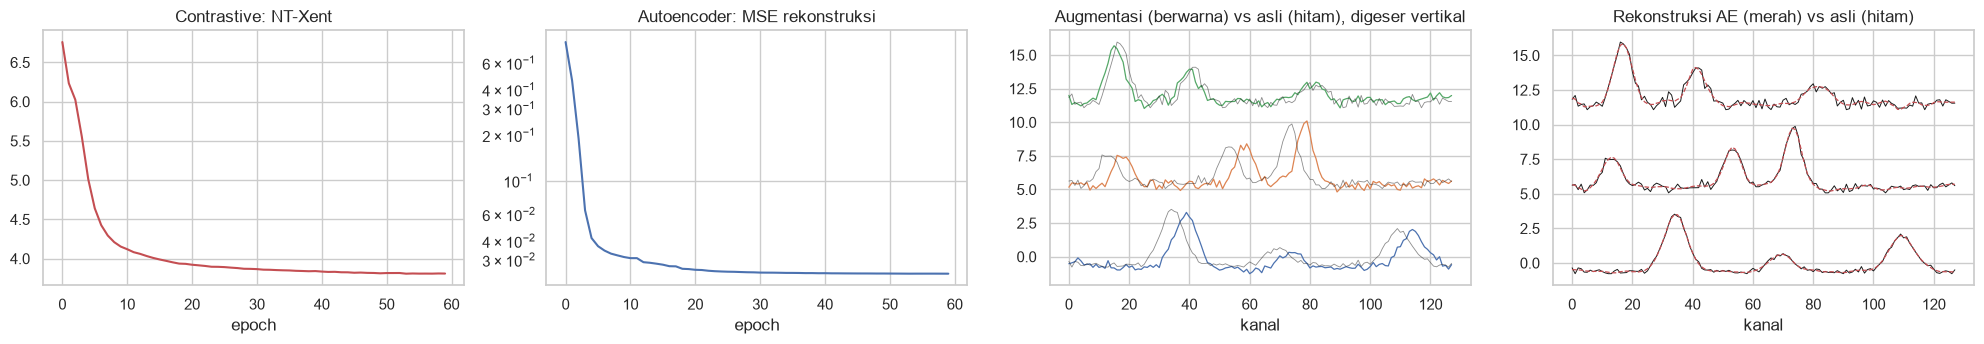

Loss akhir: contrastive = 3.8096 | AE MSE = 0.0242


In [75]:
# ---- Loss visualization + contoh augmentasi + rekonstruksi AE ----
fig, ax = plt.subplots(1, 4, figsize=(20, 3.6))
ax[0].plot(HIST_CL["loss"], c="#c44e52"); ax[0].set(title="Contrastive: NT-Xent", xlabel="epoch")
ax[1].plot(HIST_AE["loss"], c="#4c72b0"); ax[1].set(title="Autoencoder: MSE rekonstruksi", xlabel="epoch", yscale="log")
for k in range(3): ax[2].plot(AUG_DEMO[k] + 6 * k, lw=.9); ax[2].plot(X_PP[k] + 6 * k, "k", lw=.6, alpha=.5)
ax[2].set(title="Augmentasi (berwarna) vs asli (hitam), digeser vertikal", xlabel="kanal")
for k in range(3): ax[3].plot(X_PP[k] + 6 * k, "k", lw=.7); ax[3].plot(AE_RECON[k] + 6 * k, "r--", lw=.9)
ax[3].set(title="Rekonstruksi AE (merah) vs asli (hitam)", xlabel="kanal")
plt.tight_layout(); plt.show()
print(f"Loss akhir: contrastive = {HIST_CL['loss'][-1]:.4f} | AE MSE = {HIST_AE['loss'][-1]:.4f}")

## 7.x Evaluasi kualitas representasi (tanpa label)
Tiga ukuran yang tidak memerlukan label:
1. **Keterpisahan cluster** pada embedding: silhouette terbaik untuk k=2..8 dan Davies-Bouldin pada k itu.
2. **Kebocoran geseran:** seberapa baik geseran puncak per sampel (`SHIFT`, 5.3) dapat **diprediksi dari embedding** (R² regresi Ridge/kNN dengan validasi silang). Embedding yang baik harus **tidak** menyimpan distorsi, jadi R² harus rendah.
3. **Kestabilan terhadap seed** dinilai di Section 13 untuk clustering akhir.

In [76]:
def shift_leakage(E, shift, n_sample=8000):
    sub = np.random.default_rng(SEED).choice(len(E), min(n_sample, len(E)), replace=False); Zs = StandardScaler().fit_transform(E[sub]); y = shift[sub]
    p_lin = cross_val_predict(Ridge(1.0), Zs, y, cv=3); p_knn = cross_val_predict(KNeighborsRegressor(15), Zs, y, cv=3)
    return float(r2_score(y, p_lin)), float(r2_score(y, p_knn))

E_PCA = PCA(EMB_DIM, random_state=SEED).fit_transform(X_PP)
SPEC_EMB = {"PCA (baseline)": E_PCA, "Autoencoder": E_AE, "Contrastive (aug. geser)": E_CL}
rows = []
for nm, E in SPEC_EMB.items():
    q = cluster_quality(E); b = q.loc[q["silhouette"].idxmax()]; r2l, r2k = shift_leakage(E, SHIFT)
    rows.append({"representasi": nm, "dim": E.shape[1], "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"],
                 "R2 geseran (linear)": r2l, "R2 geseran (kNN)": r2k})
tab_rep = pd.DataFrame(rows); print(tab_rep.round(3).to_string(index=False))
tab_rep.to_csv(OUTPUT_DIR / "evaluasi_representasi_spektrum.csv", index=False)

# Representasi spektrum untuk fusion: pilih dari model deep learning (PCA = pembanding) dengan silhouette terbaik
dl = tab_rep[tab_rep["representasi"] != "PCA (baseline)"]
SPEC_NAME = dl.loc[dl["silhouette terbaik"].idxmax(), "representasi"]; E_SPEC = SPEC_EMB[SPEC_NAME]
print(f"\nRepresentasi spektrum terpilih untuk fusion: {SPEC_NAME} ({E_SPEC.shape})")

            representasi  dim  silhouette terbaik  pada k  DB di k itu  R2 geseran (linear)  R2 geseran (kNN)
          PCA (baseline)   32               0.483       4        0.866                0.703             0.796
             Autoencoder   32               0.471       4        0.872                0.647             0.824
Contrastive (aug. geser)   32               0.422       8        0.913                0.058             0.026

Representasi spektrum terpilih untuk fusion: Autoencoder ((36000, 32))


**Interpretasi.** Kolom *R² geseran* menunjukkan seberapa banyak informasi geseran (distorsi) yang masih tersimpan; **semakin rendah semakin baik**. PCA dan autoencoder dilatih hanya untuk merekonstruksi/menjelaskan varians sehingga
cenderung menyimpan geseran, sedangkan contrastive encoder dilatih dengan augmentasi geser agar tidak peduli terhadapnya. Bandingkan juga *silhouette terbaik*: bila embedding invarian geseran, satu jenis material tidak lagi terbelah menjadi dua,
sehingga cluster lebih padat dan terpisah. Representasi dengan silhouette terbaik di antara model deep learning dipakai pada fusion. Angka persisnya bergantung pada hasil training, jadi **baca tabel di atas, bukan teks ini**,
dan jika contrastive tidak unggul, laporkan apa adanya (itu juga temuan yang sah).

# SECTION 8 — Multimodal Fusion

Menggabungkan **embedding spektrum** (Section 7) dan **embedding gambar** (Anggota 1, Section 6). Strategi yang dibandingkan:

| Strategi | Cara kerja | Alasan |
|---|---|---|
| **Concat skala-blok** (bobot gambar 0,5 / 1 / 2) | tiap modality dipusatkan dan diskalakan agar norma baris rata-rata = 1, lalu digabung | sederhana; skala-blok mencegah modality berdimensi besar mendominasi hanya karena dimensinya; bobot menguji "seberapa penting gambar" |
| **Concat PCA-whitened** (16 + 16) | tiap modality diputihkan (PCA whiten) ke 16 komponen, lalu digabung | setiap arah variasi bermakna punya bobot setara; meredam arah ber-varians-besar yang hanya noise/domain |
| **CCA** (16 komponen kanonik) | proyeksi ke ruang bersama yang paling berkorelasi antar-modality | menangkap struktur yang **konsisten di kedua modality** dan membuang variasi yang hanya ada di satu sisi (mis. kecerahan mikroskop pada gambar) |

Pemilihan strategi memakai ukuran **tanpa label** (silhouette terbaik/Davies-Bouldin, Section 5.2) pada hasil fusion, dan **tidak** memakai label referensi. Silhouette cenderung menyukai ruang yang didominasi modality yang cluster-nya paling rapat,
jadi hasilnya dibaca bersama analisis "apa yang hilang bila satu modality" (Section 11 dan 13), bukan sebagai kebenaran mutlak.

**Hipotesis yang diuji (bukan fakta):** pada beberapa contoh gambar, satu kelompok spektral tampak memuat **lebih dari satu tekstur gambar** (mis. bercak gelap vs pola labirin). Bila benar, gambar memisahkan jenis material yang spektrumnya tidak bisa membedakan.

In [77]:
def block_scale(E):
    E = np.asarray(E, np.float64); E = E - E.mean(0)
    return (E / np.sqrt((E ** 2).sum(1).mean())).astype(np.float32)            # norma baris rata-rata = 1 -> sumbangan modality setara

def whiten_pca(E, n=16):
    E = np.asarray(E, np.float64)
    return PCA(min(n, E.shape[1]), whiten=True, random_state=SEED).fit_transform(E - E.mean(0)).astype(np.float32)

def cca_fusion(Es, Ei, n=16):
    A, B = whiten_pca(Es, 32), whiten_pca(Ei, 32)                              # setelah diputihkan, kovarians silang = korelasi kanonik
    U, S, Vt = np.linalg.svd(A.T @ B / len(A), full_matrices=False); n = min(n, len(S))
    return np.hstack([A @ U[:, :n], B @ Vt.T[:, :n]]).astype(np.float32), S[:n]

def knn_overlap(A, B, k=10, n=3000, shuffle=False):
    # Rata-rata irisan k-tetangga terdekat di ruang A vs ruang B untuk sampel yang SAMA. Jika pairing benar, > acak.
    rg = np.random.default_rng(SEED); sub = rg.choice(len(A), n, replace=False); A, B = A[sub], B[sub]
    if shuffle: B = B[rg.permutation(n)]
    nA = NearestNeighbors(n_neighbors=k + 1).fit(A).kneighbors(A, return_distance=False)[:, 1:]
    nB = NearestNeighbors(n_neighbors=k + 1).fit(B).kneighbors(B, return_distance=False)[:, 1:]
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(nA, nB)]))

FUSIONS, FUSION_TABLE = {}, None
if not HAS_IMG:
    print("=" * 100); print("FUSION DIHENTIKAN: embedding gambar Anggota 1 belum tersedia (lihat Section 6).")
    print("Section 9 dst. memakai embedding SPEKTRUM saja sebagai mode sementara; hasilnya bukan hasil akhir dan cluster.csv final tidak ditulis.")
    print("=" * 100)
    E_FUSED, FUSION_NAME = E_SPEC, f"(spektrum saja) {SPEC_NAME}"
else:
    # ---- 8.1 Pemeriksaan pairing ID: statistik ----
    assert E_IMG.shape[0] == E_SPEC.shape[0] == N == len(IDS), "jumlah baris berbeda antar-modality"
    Zs, Zi = prep_for_cluster(E_SPEC), prep_for_cluster(E_IMG)
    ov_real, ov_shuf = knn_overlap(Zs, Zi), knn_overlap(Zs, Zi, shuffle=True)
    print(f"Pairing: irisan 10-tetangga spektrum vs gambar = {ov_real:.4f} | kontrol (pairing diacak) = {ov_shuf:.4f} | acak teoritis ~ {10 / 3000:.4f}")
    if ov_real < 2 * ov_shuf:
        print("PERINGATAN: irisan tidak jauh di atas acak. Periksa lagi urutan/ID embedding gambar (mungkin pairing salah) sebelum melanjutkan!")
    else:
        print("OK: tetangga terdekat di kedua modality jauh lebih sering sama daripada acak -> pairing konsisten.")

    # ---- 8.2 Strategi fusion ----
    Bs, Bi = block_scale(E_SPEC), block_scale(E_IMG)
    FUSIONS["Concat skala-blok (w_gambar=0.5)"] = np.hstack([Bs, 0.5 * Bi])
    FUSIONS["Concat skala-blok (w_gambar=1)"] = np.hstack([Bs, Bi])
    FUSIONS["Concat skala-blok (w_gambar=2)"] = np.hstack([Bs, 2.0 * Bi])
    FUSIONS["Concat PCA-whitened (16+16)"] = np.hstack([whiten_pca(E_SPEC, 16), whiten_pca(E_IMG, 16)])
    FUSIONS["CCA (16 komponen)"], cca_corr = cca_fusion(E_SPEC, E_IMG, 16)
    print(f"Korelasi kanonik (5 pertama): {np.round(cca_corr[:5], 3).tolist()}")

    rows = []
    for nm, E in [("Spektrum saja", E_SPEC), ("Gambar saja", E_IMG)] + list(FUSIONS.items()):
        assert E.shape[0] == N and np.isfinite(E).all(), nm
        q = cluster_quality(E); b = q.loc[q["silhouette"].idxmax()]
        rows.append({"representasi": nm, "dim": E.shape[1], "silhouette terbaik": b["silhouette"], "pada k": int(b["k"]), "DB di k itu": b["DB"]})
    FUSION_TABLE = pd.DataFrame(rows); print("\n" + FUSION_TABLE.round(3).to_string(index=False))
    FUSION_TABLE.to_csv(OUTPUT_DIR / "perbandingan_fusion.csv", index=False)

    cand = FUSION_TABLE[FUSION_TABLE["representasi"].isin(FUSIONS)]
    FUSION_NAME = cand.loc[cand["silhouette terbaik"].idxmax(), "representasi"]; E_FUSED = FUSIONS[FUSION_NAME]
    print(f"\nStrategi fusion terpilih: {FUSION_NAME} | dimensi hasil fusion = {E_FUSED.shape} (baris = {N} = jumlah sampel; urutan = urutan meta)")
np.save(OUTPUT_DIR / "emb_fusi.npy", E_FUSED)

Pairing: irisan 10-tetangga spektrum vs gambar = 0.0137 | kontrol (pairing diacak) = 0.0037 | acak teoritis ~ 0.0033
OK: tetangga terdekat di kedua modality jauh lebih sering sama daripada acak -> pairing konsisten.
Korelasi kanonik (5 pertama): [0.9620000123977661, 0.9120000004768372, 0.9010000228881836, 0.050999999046325684, 0.04899999871850014]

                    representasi  dim  silhouette terbaik  pada k  DB di k itu
                   Spektrum saja   32               0.471       4        0.872
                     Gambar saja   32               0.362       7        1.013
Concat skala-blok (w_gambar=0.5)   64               0.426       5        1.037
  Concat skala-blok (w_gambar=1)   64               0.405       6        1.019
  Concat skala-blok (w_gambar=2)   64               0.384       8        0.970
     Concat PCA-whitened (16+16)   32               0.195       4        1.935
               CCA (16 komponen)   32               0.198       4        1.889

Strategi fusion 

**Interpretasi.** Baca tabel di atas dengan tiga pertanyaan: **(1)** apakah gabungan lebih baik daripada spektrum saja dan gambar saja pada keterpisahan cluster? **(2)** apakah *k terbaik* berubah ketika gambar ditambahkan
(kolom "pada k"; jika naik, gambar membuka pembagian halus yang tidak terlihat di spektrum)? **(3)** apakah bobot gambar yang berbeda mengubah kesimpulan? Pemeriksaan pairing (irisan tetangga vs kontrol acak) memastikan baris spektrum dan gambar
benar-benar berpasangan; bila irisannya tidak jauh di atas acak, **hentikan** dan periksa ID embedding sebelum clustering. Alasan pemilihan strategi terakhir dibahas di Section 14.

# SECTION 9 — Clustering Method 1: KMeans (dan GMM sebagai pembanding)

* **KMeans** (`n_init=10`, jarak Euclid) dan **Gaussian Mixture** (kovarians penuh) pada embedding fusi yang direduksi **PCA 16-d** (`E_CL16`), untuk k = 2…12.
* **Hyperparameter:** `k` adalah satu-satunya hyperparameter utama; ditentukan dengan **aturan agregasi peringkat** atas silhouette, Davies-Bouldin, dan kestabilan (ARI antar-resampling). Calinski-Harabasz dan BIC-GMM dilaporkan sebagai bukti pendukung.
  Pembahasan lengkap kriteria ada di **Section 11**; aturan pemilihannya didefinisikan di sini karena DEC (Section 10) memerlukan `k`.
* **Cluster assignment** untuk semua k disimpan di `OUTPUT_DIR`.

In [78]:
E_CL16 = prep_for_cluster(E_FUSED)                          # ruang clustering seragam untuk semua metode (PCA 16-d)
print("Ruang clustering:", E_CL16.shape, "| MODE =", MODE)

def internal_metrics(Z, lab, n_sample=8000):
    sub = np.random.default_rng(SEED).choice(len(Z), min(n_sample, len(Z)), replace=False)
    return float(silhouette_score(Z[sub], lab[sub])), float(davies_bouldin_score(Z, lab)), float(calinski_harabasz_score(Z, lab))

def stability_ari(Z, k, n_rep=N_STAB, frac=0.7):
    # Kestabilan: dua KMeans pada subsampel 70% berbeda; label semua titik diprediksi lalu dibandingkan (ARI). 1 = identik.
    rg = np.random.default_rng(SEED); sc = []
    for r in range(n_rep):
        a, b = rg.choice(len(Z), int(frac * len(Z)), replace=False), rg.choice(len(Z), int(frac * len(Z)), replace=False)
        ma = KMeans(k, n_init=3, random_state=SEED + r).fit(Z[a]); mb = KMeans(k, n_init=3, random_state=SEED + 100 + r).fit(Z[b])
        sc.append(adjusted_rand_score(ma.predict(Z), mb.predict(Z)))
    return float(np.mean(sc)), float(np.std(sc))

LABELS_KM, LABELS_GMM, rows = {}, {}, []
t0 = time.time()
for k in K_RANGE:
    km = KMeans(k, n_init=N_INIT, random_state=SEED).fit(E_CL16); LABELS_KM[k] = km.labels_
    gm = GaussianMixture(k, covariance_type="full", n_init=2, random_state=SEED).fit(E_CL16); LABELS_GMM[k] = gm.predict(E_CL16)
    s, db, ch = internal_metrics(E_CL16, km.labels_); st, st_sd = stability_ari(E_CL16, k)
    rows.append({"k": k, "silhouette": s, "DB": db, "CH": ch, "stabilitas_ARI": st, "stab_sd": st_sd, "inertia": km.inertia_,
                 "GMM_BIC": gm.bic(E_CL16), "GMM_silhouette": internal_metrics(E_CL16, LABELS_GMM[k])[0]})
SWEEP = pd.DataFrame(rows).set_index("k"); print(f"Sweep k selesai dalam {time.time() - t0:.0f} dtk"); print(SWEEP.round(3).to_string())
SWEEP.to_csv(OUTPUT_DIR / "sweep_k.csv")

Ruang clustering: (36000, 16) | MODE = multimodal
Sweep k selesai dalam 41 dtk
    silhouette     DB         CH  stabilitas_ARI  stab_sd    inertia      GMM_BIC  GMM_silhouette
k                                                                                                
2        0.261  1.753  11342.614           0.695    0.371  32594.959  -847667.768           0.222
3        0.372  1.221  15192.994           1.000    0.000  23244.246 -1096143.067           0.372
4        0.414  1.069  17986.221           0.998    0.001  17152.859 -1274331.106           0.411
5        0.426  1.033  16493.700           0.836    0.081  15131.311 -1323469.653           0.426
6        0.383  1.137  15752.417           0.805    0.099  13444.993 -1345503.589           0.400
7        0.353  1.170  15539.612           0.850    0.117  11938.746 -1373303.805           0.351
8        0.333  1.176  15856.579           0.881    0.094  10496.148 -1381247.244           0.358
9        0.329  1.134  15430.339       

In [79]:
def select_k(sweep):
    # Agregasi peringkat: peringkat tiap kriteria (1 = terbaik) dirata-rata; k dengan rata-rata terkecil menang; seri -> k lebih kecil (parsimoni)
    crit = {"silhouette": (sweep["silhouette"], True), "DB": (sweep["DB"], False), "stabilitas_ARI": (sweep["stabilitas_ARI"], True)}
    ranks = pd.DataFrame({n: v.rank(ascending=not hi, method="min") for n, (v, hi) in crit.items()})
    mean_rank = ranks.mean(1); return int(mean_rank.idxmin()), ranks, mean_rank

K_SEL, RANKS, MEAN_RANK = select_k(SWEEP)
PICKS = {"silhouette (maks)": int(SWEEP["silhouette"].idxmax()), "Davies-Bouldin (min)": int(SWEEP["DB"].idxmin()),
         "stabilitas ARI (maks)": int(SWEEP["stabilitas_ARI"].idxmax()), "Calinski-Harabasz (maks)": int(SWEEP["CH"].idxmax()), "BIC GMM (min)": int(SWEEP["GMM_BIC"].idxmin())}
print("k pilihan tiap kriteria:", PICKS); print("Rata-rata peringkat (silhouette, DB, stabilitas):"); print(MEAN_RANK.round(2).to_dict())
print(f"\n>>> K_SEL = {K_SEL}")

labels_km, labels_gmm = LABELS_KM[K_SEL], LABELS_GMM[K_SEL]
np.savez(OUTPUT_DIR / "assign_kmeans_gmm.npz", ids=IDS, k_values=np.array(K_RANGE),
         **{f"km_k{k}": LABELS_KM[k] for k in K_RANGE}, **{f"gmm_k{k}": LABELS_GMM[k] for k in K_RANGE})
print(f"KMeans (k={K_SEL}) ukuran cluster:", np.bincount(labels_km).tolist()); print(f"GMM    (k={K_SEL}) ukuran cluster:", np.bincount(labels_gmm, minlength=K_SEL).tolist())

k pilihan tiap kriteria: {'silhouette (maks)': 5, 'Davies-Bouldin (min)': 5, 'stabilitas ARI (maks)': 3, 'Calinski-Harabasz (maks)': 4, 'BIC GMM (min)': 12}
Rata-rata peringkat (silhouette, DB, stabilitas):
{2: 11.0, 3: 5.0, 4: 2.0, 5: 2.67, 6: 5.33, 7: 6.0, 8: 6.0, 9: 5.0, 10: 6.33, 11: 8.33, 12: 8.33}

>>> K_SEL = 4
KMeans (k=4) ukuran cluster: [10030, 8655, 8689, 8626]
GMM    (k=4) ukuran cluster: [10044, 8637, 8684, 8635]


# SECTION 10 — Clustering Method 2: Deep Embedded Clustering (DEC)

**Arsitektur.** Autoencoder MLP pada embedding fusi (distandardisasi): encoder `D → 256 → 128 → 10` dan decoder simetris. Lapisan tambahan berupa **pusat cluster** `μ_j ∈ R^10` (parameter yang dapat dilatih), j = 1…k.

**Tahap 1 — pra-latih** autoencoder dengan MSE rekonstruksi. **Tahap 2 — inisialisasi** `μ_j` dengan KMeans pada latent. **Tahap 3 — DEC:**

* **Soft assignment (Student-t):** `q_ij = (1 + ||z_i − μ_j||²)^−1 / Σ_j' (1 + ||z_i − μ_j'||²)^−1`
* **Target distribution (mempertajam):** `p_ij = (q_ij² / f_j) / Σ_j' (q_ij'² / f_j')`, dengan `f_j = Σ_i q_ij` (normalisasi frekuensi cluster agar cluster besar tidak mendominasi)
* **Fungsi tujuan:** `L = KL(P ‖ Q) + γ · MSE(x, x̂)`, `γ = 0,1`. Suku KL menarik titik ke cluster yang sudah paling yakin ditempati; suku rekonstruksi (varian IDEC) menjaga latent tidak rusak.
* `P` dihitung ulang pada **awal tiap epoch** (seluruh data), pelatihan memakai **mini-batch** 1.024 dan Adam. **Berhenti** bila persentase label yang berubah antar-epoch < 0,1%.

`k` memakai `K_SEL` dari Section 9. Embedding, bobot, dan assignment disimpan agar tidak perlu melatih ulang.

In [80]:
import hashlib

class DECNet(nn.Module):
    def __init__(self, in_dim, k, hid=(256, 128), lat=DEC_LATENT):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, hid[0]), nn.ReLU(), nn.Linear(hid[0], hid[1]), nn.ReLU(), nn.Linear(hid[1], lat))
        self.dec = nn.Sequential(nn.Linear(lat, hid[1]), nn.ReLU(), nn.Linear(hid[1], hid[0]), nn.ReLU(), nn.Linear(hid[0], in_dim))
        self.centers = nn.Parameter(torch.zeros(k, lat))
    def soft_assign(self, z, alpha=1.0):
        d2 = torch.cdist(z, self.centers) ** 2; q = (1.0 + d2 / alpha) ** (-(alpha + 1.0) / 2.0)
        return q / q.sum(1, keepdim=True)

def target_distribution(q):
    w = q ** 2 / q.sum(0, keepdim=True); return w / w.sum(1, keepdim=True)

def run_dec(E, k, bs=1024):
    Xs = StandardScaler().fit_transform(E).astype(np.float32); X = torch.from_numpy(Xs).to(DEVICE); n, d = X.shape
    net = DECNet(d, k).to(DEVICE); hist = {"pretrain_loss": [], "dec_loss": [], "delta": []}
    # ---- Tahap 1: pra-latih autoencoder ----
    opt = torch.optim.Adam(list(net.enc.parameters()) + list(net.dec.parameters()), lr=1e-3)
    for ep in range(DEC_PRETRAIN_EPOCHS):
        net.train(); perm = torch.randperm(n, device=DEVICE); run = 0.0; nb = max(n // bs, 1)
        for i in range(nb):
            xb = X[perm[i * bs:(i + 1) * bs]]; loss = F.mse_loss(net.dec(net.enc(xb)), xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); run += loss.item()
        hist["pretrain_loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 20 == 0: print(f"[DEC pra-latih] epoch {ep + 1:03d}/{DEC_PRETRAIN_EPOCHS} | MSE = {run / nb:.4f}")
    # ---- Tahap 2: inisialisasi pusat dengan KMeans pada latent ----
    net.eval()
    with torch.no_grad(): Z0 = net.enc(X).cpu().numpy()
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z0); net.centers.data = torch.from_numpy(km.cluster_centers_.astype(np.float32)).to(DEVICE); prev = km.labels_
    # ---- Tahap 3: DEC ----
    opt = torch.optim.Adam(net.parameters(), lr=DEC_LR)
    for ep in range(DEC_EPOCHS):
        net.eval()
        with torch.no_grad(): Q = net.soft_assign(net.enc(X)); P = target_distribution(Q)
        lab = Q.argmax(1).cpu().numpy(); delta = float((lab != prev).mean()); prev = lab; hist["delta"].append(delta)
        if ep >= 5 and delta < DEC_TOL:
            print(f"[DEC] berhenti di epoch {ep}: label berubah {delta * 100:.3f}% < {DEC_TOL * 100:.1f}%"); break
        net.train(); perm = torch.randperm(n, device=DEVICE); run = 0.0; nb = max(n // bs, 1)
        for i in range(nb):
            idx = perm[i * bs:(i + 1) * bs]; xb = X[idx]; z = net.enc(xb); q = net.soft_assign(z)
            loss = F.kl_div(q.clamp_min(1e-8).log(), P[idx], reduction="batchmean") + DEC_GAMMA * F.mse_loss(net.dec(z), xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); run += loss.item()
        hist["dec_loss"].append(run / nb)
        if ep == 0 or (ep + 1) % 10 == 0: print(f"[DEC] epoch {ep + 1:03d} | loss = {run / nb:.4f} | label berubah = {delta * 100:.2f}%")
    net.eval()
    with torch.no_grad(): Zf = net.enc(X); labels = net.soft_assign(Zf).argmax(1).cpu().numpy(); Zf = Zf.cpu().numpy()
    return net, hist, labels, Zf

def run_dec_cached(E, k):
    tag = f"dec_{MODE}_k{k}_{hashlib.md5(np.ascontiguousarray(E, dtype=np.float32).tobytes()).hexdigest()[:8]}"     # cache dikunci ke isi embedding
    f = OUTPUT_DIR / f"{tag}.npz"
    if f.exists() and not RETRAIN:
        z = np.load(f, allow_pickle=False); print(f"[DEC] dimuat dari cache {f}"); return z["labels"], z["Z"], json.loads(str(z["hist"]))
    net, hist, labels, Z = run_dec(E, k); torch.save(net.state_dict(), OUTPUT_DIR / f"{tag}.pt")
    np.savez(f, labels=labels, Z=Z, hist=json.dumps(hist)); return labels, Z, hist

In [81]:
# [TORCH-RUN] DEC: latih Deep Embedded Clustering pada embedding fusi (atau muat dari cache)
set_seed(); LABELS_DEC, Z_DEC, HIST_DEC = run_dec_cached(E_FUSED, K_SEL)
np.save(OUTPUT_DIR / "assign_dec.npy", LABELS_DEC)
print(f"DEC (k={K_SEL}) ukuran cluster:", np.bincount(LABELS_DEC, minlength=K_SEL).tolist(), "| dimensi latent:", Z_DEC.shape)

[DEC pra-latih] epoch 001/60 | MSE = 0.6155
[DEC pra-latih] epoch 020/60 | MSE = 0.0366
[DEC pra-latih] epoch 040/60 | MSE = 0.0302
[DEC pra-latih] epoch 060/60 | MSE = 0.0281
[DEC] epoch 001 | loss = 0.0556 | label berubah = 0.00%
[DEC] berhenti di epoch 5: label berubah 0.000% < 0.1%
DEC (k=4) ukuran cluster: [8630, 8692, 8633, 10045] | dimensi latent: (36000, 10)


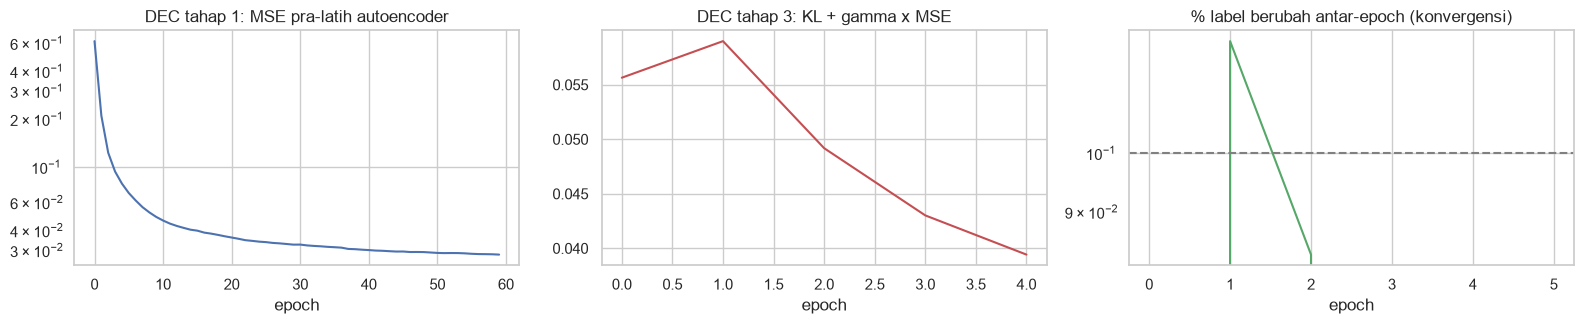

ARI DEC vs KMeans (k=4): 0.946 | vs GMM: 0.999


In [82]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
ax[0].plot(HIST_DEC["pretrain_loss"]); ax[0].set(title="DEC tahap 1: MSE pra-latih autoencoder", xlabel="epoch", yscale="log")
ax[1].plot(HIST_DEC["dec_loss"], c="#c44e52"); ax[1].set(title="DEC tahap 3: KL + gamma x MSE", xlabel="epoch")
ax[2].plot(np.array(HIST_DEC["delta"]) * 100, c="#55a868"); ax[2].axhline(DEC_TOL * 100, ls="--", c="gray"); ax[2].set(title="% label berubah antar-epoch (konvergensi)", xlabel="epoch", yscale="log")
plt.tight_layout(); plt.show()
print(f"ARI DEC vs KMeans (k={K_SEL}): {adjusted_rand_score(LABELS_DEC, labels_km):.3f} | vs GMM: {adjusted_rand_score(LABELS_DEC, labels_gmm):.3f}")

**Interpretasi.** Loss KL turun dan persentase label yang berubah mendekati nol menandakan DEC konvergen ke partisi yang stabil. Perbandingan ARI antara DEC dan KMeans/GMM menunjukkan seberapa jauh pelatihan mendalam
**mengubah** partisi dibanding clustering klasik pada ruang yang sama; ARI mendekati 1 berarti DEC hanya mempertajam partisi yang sudah ada, nilai rendah berarti DEC menemukan struktur berbeda (nilai persisnya dibahas di Section 13–14).

# SECTION 11 — Number of Clusters Selection

Syarat: **minimal dua kriteria**. Yang dipakai: **Silhouette**, **Davies-Bouldin**, **Calinski-Harabasz**, **BIC (GMM)**, dan **kestabilan ARI** antar-resampling (partisi yang benar harus muncul ulang pada subsampel berbeda).
Keputusan akhir memakai agregasi peringkat atas tiga kriteria yang tidak monoton terhadap k (silhouette, Davies-Bouldin, kestabilan; Section 9).
Calinski-Harabasz dan BIC dilaporkan sebagai pendukung karena cenderung terus membaik pada k besar (BIC untuk 36.000 sampel hampir selalu menyukai lebih banyak komponen).

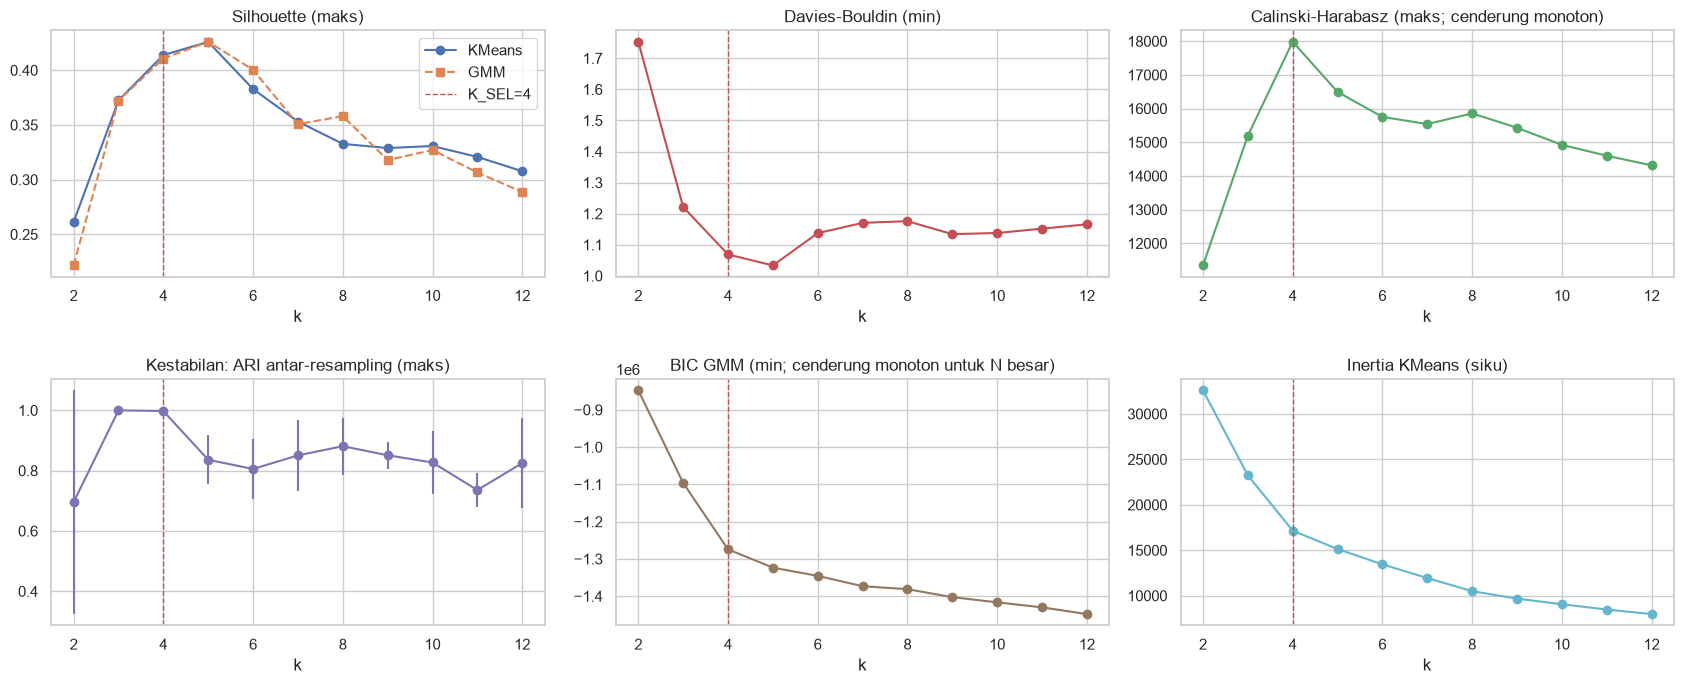

            silhouette (maks)  Davies-Bouldin (min)  stabilitas ARI (maks)  Calinski-Harabasz (maks)  BIC GMM (min)
k terpilih                  5                     5                      3                         4             12
Rata-rata peringkat tiap k (kecil = baik): {2: 11.0, 3: 5.0, 4: 2.0, 5: 2.67, 6: 5.33, 7: 6.0, 8: 6.0, 9: 5.0, 10: 6.33, 11: 8.33, 12: 8.33}
=> K_SEL = 4


In [83]:
fig, ax = plt.subplots(2, 3, figsize=(17, 7)); ks = SWEEP.index.values
def mark(a): a.axvline(K_SEL, c="r", ls="--", lw=1, label=f"K_SEL={K_SEL}")
ax[0, 0].plot(ks, SWEEP["silhouette"], "o-", label="KMeans"); ax[0, 0].plot(ks, SWEEP["GMM_silhouette"], "s--", label="GMM"); mark(ax[0, 0]); ax[0, 0].set(title="Silhouette (maks)", xlabel="k"); ax[0, 0].legend()
ax[0, 1].plot(ks, SWEEP["DB"], "o-", c="#c44e52"); mark(ax[0, 1]); ax[0, 1].set(title="Davies-Bouldin (min)", xlabel="k")
ax[0, 2].plot(ks, SWEEP["CH"], "o-", c="#55a868"); mark(ax[0, 2]); ax[0, 2].set(title="Calinski-Harabasz (maks; cenderung monoton)", xlabel="k")
ax[1, 0].errorbar(ks, SWEEP["stabilitas_ARI"], yerr=SWEEP["stab_sd"], fmt="o-", c="#8172b2"); mark(ax[1, 0]); ax[1, 0].set(title="Kestabilan: ARI antar-resampling (maks)", xlabel="k")
ax[1, 1].plot(ks, SWEEP["GMM_BIC"], "o-", c="#937860"); mark(ax[1, 1]); ax[1, 1].set(title="BIC GMM (min; cenderung monoton untuk N besar)", xlabel="k")
ax[1, 2].plot(ks, SWEEP["inertia"], "o-", c="#64b5cd"); mark(ax[1, 2]); ax[1, 2].set(title="Inertia KMeans (siku)", xlabel="k")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k terpilih": PICKS}).T.to_string()); print("Rata-rata peringkat tiap k (kecil = baik):", MEAN_RANK.round(2).to_dict()); print(f"=> K_SEL = {K_SEL}")

In [84]:
# k terbaik menurut tiap modality: apa yang berubah ketika modality ditambahkan/dibuang?
mod_sets = {"Spektrum saja": E_SPEC}
if HAS_IMG: mod_sets.update({"Gambar saja": E_IMG, f"Fusi ({FUSION_NAME})": E_FUSED})
rows = []
for nm, E in mod_sets.items():
    q = cluster_quality(E, ks=range(2, 10)); rows.append({"modality": nm, "k terbaik (silhouette)": int(q.loc[q['silhouette'].idxmax(), 'k']), "silhouette": q['silhouette'].max(),
                                                          "k terbaik (DB)": int(q.loc[q['DB'].idxmin(), 'k']), "DB": q['DB'].min()})
MOD_PICKS = pd.DataFrame(rows); print(MOD_PICKS.round(3).to_string(index=False))
if not HAS_IMG: print("\n(Perbandingan gambar-saja/fusi menunggu embedding gambar Anggota 1.)")

                               modality  k terbaik (silhouette)  silhouette  k terbaik (DB)    DB
                          Spektrum saja                       4       0.471               4 0.872
                            Gambar saja                       9       0.388               9 0.941
Fusi (Concat skala-blok (w_gambar=0.5))                       5       0.426               5 1.037


**Interpretasi.** Kriteria yang berbeda memang boleh memilih k yang berbeda; itu bukan kesalahan, melainkan tanda **struktur hierarkis** (kelompok kasar yang terbagi lagi menjadi kelompok halus). Silhouette dan Davies-Bouldin biasanya menyukai partisi **kasar** yang paling rapat,
sedangkan Calinski-Harabasz, BIC, dan inertia mendorong ke k yang lebih besar. Karena itu keputusan memakai gabungan peringkat dengan **kestabilan** sebagai penyeimbang: partisi halus yang tidak muncul ulang pada subsampel berbeda
(mis. pembagian yang hanya mengikuti geseran puncak spektrum, Section 5.3) mendapat kestabilan rendah dan tidak dipilih. Tabel "k terbaik menurut modality" memperlihatkan **apa yang hilang bila satu modality dipakai**: bila k terbaik pada fusi
lebih besar daripada pada spektrum saja, gambar membuka pembagian jenis material yang tidak terlihat dari spektrum.

# SECTION 12 — Visualization

UMAP (seluruh 36.000 sampel) dan t-SNE (subsampel 6.000, karena t-SNE jauh lebih lambat) pada ruang clustering yang sama (`E_CL16`). Dibandingkan: KMeans, GMM, DEC, serta pewarnaan menurut **mikroskop** (untuk memeriksa pengaruh domain shift).

UMAP selesai 28 dtk
t-SNE selesai 15 dtk


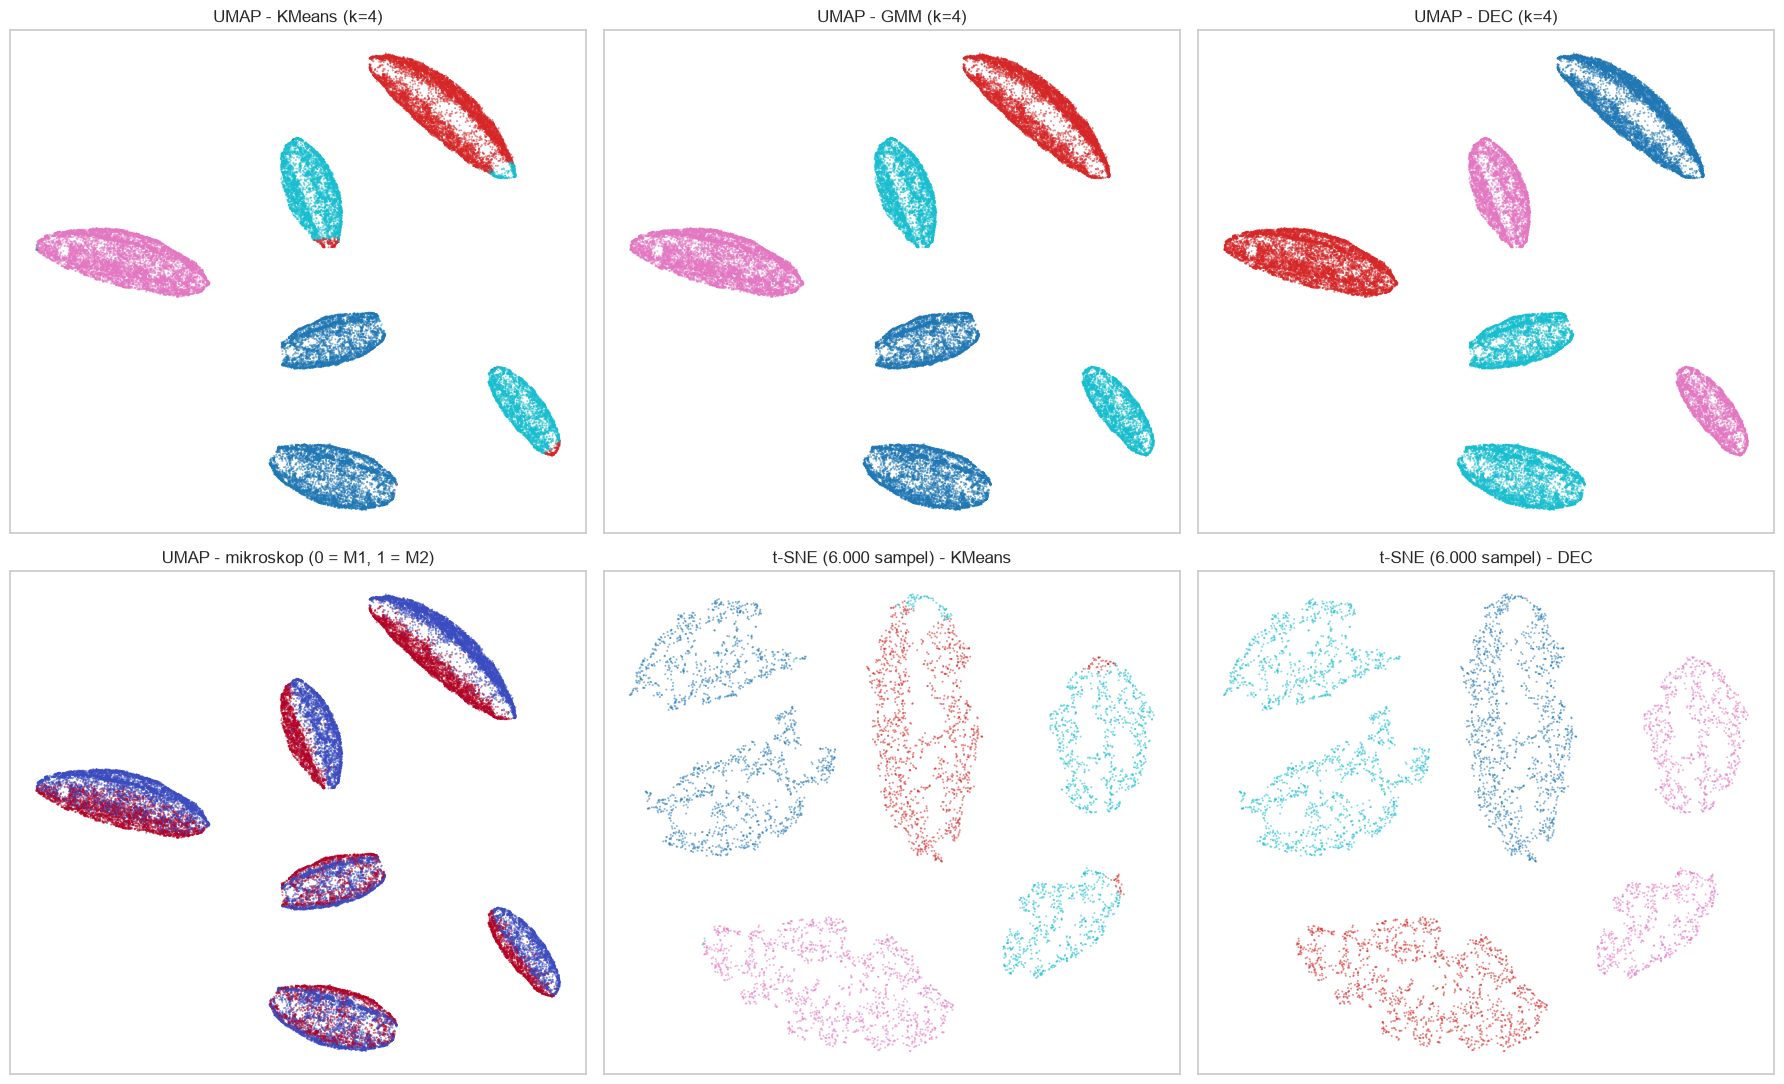

In [85]:
t0 = time.time(); UMAP_XY = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(E_CL16); print(f"UMAP selesai {time.time() - t0:.0f} dtk")
TS_IDX = np.random.default_rng(SEED).choice(N, 6000, replace=False); t0 = time.time()
TSNE_XY = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(E_CL16[TS_IDX]); print(f"t-SNE selesai {time.time() - t0:.0f} dtk")
np.save(OUTPUT_DIR / "umap_xy.npy", UMAP_XY); np.save(OUTPUT_DIR / "tsne_xy.npy", TSNE_XY)

def scatter(ax, xy, lab, title, cmap=None):
    cm = cmap or ("tab10" if len(np.unique(lab)) <= 10 else "tab20"); ax.scatter(xy[:, 0], xy[:, 1], c=lab, cmap=cm, s=2, alpha=.55, linewidths=0)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(2, 3, figsize=(18, 11))
scatter(ax[0, 0], UMAP_XY, labels_km, f"UMAP - KMeans (k={K_SEL})"); scatter(ax[0, 1], UMAP_XY, labels_gmm, f"UMAP - GMM (k={K_SEL})"); scatter(ax[0, 2], UMAP_XY, LABELS_DEC, f"UMAP - DEC (k={K_SEL})")
scatter(ax[1, 0], UMAP_XY, MIC, "UMAP - mikroskop (0 = M1, 1 = M2)", cmap="coolwarm")
scatter(ax[1, 1], TSNE_XY, labels_km[TS_IDX], "t-SNE (6.000 sampel) - KMeans"); scatter(ax[1, 2], TSNE_XY, LABELS_DEC[TS_IDX], "t-SNE (6.000 sampel) - DEC")
plt.tight_layout(); plt.show()

 cluster     n  silhouette rata2  % titik batas (sil < 0.1)  cluster tetangga terdekat  jarak ke tetangga
       0 10030             0.434                      0.861                          1              1.374
       1  8655             0.440                      1.896                          3              1.188
       2  8689             0.498                      0.481                          3              1.412
       3  8626             0.285                     11.446                          1              1.188

Pasangan cluster paling berdekatan: 1 dan 3 (jarak pusat = 1.188); cluster paling tidak terpisah: 3


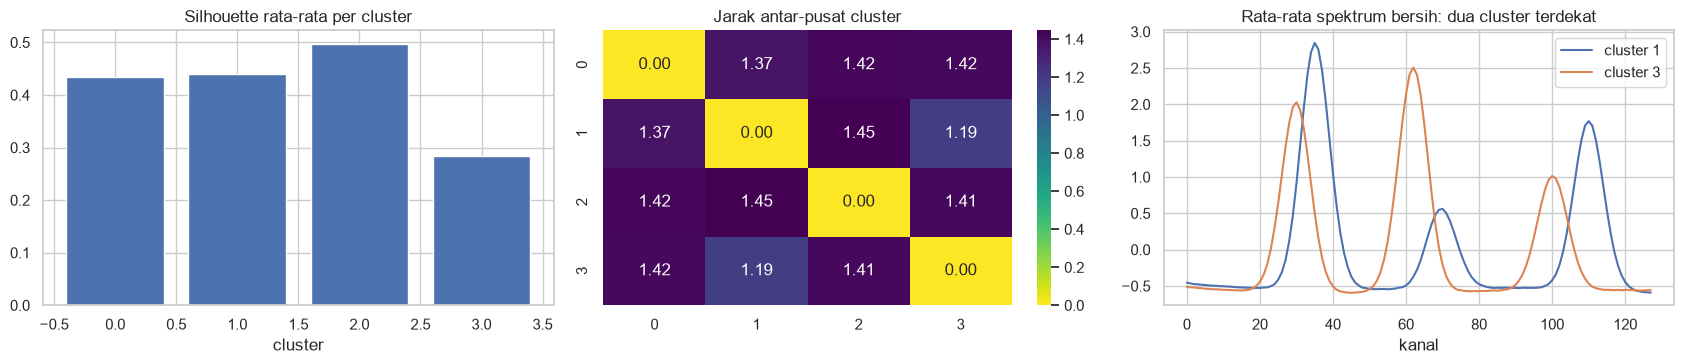

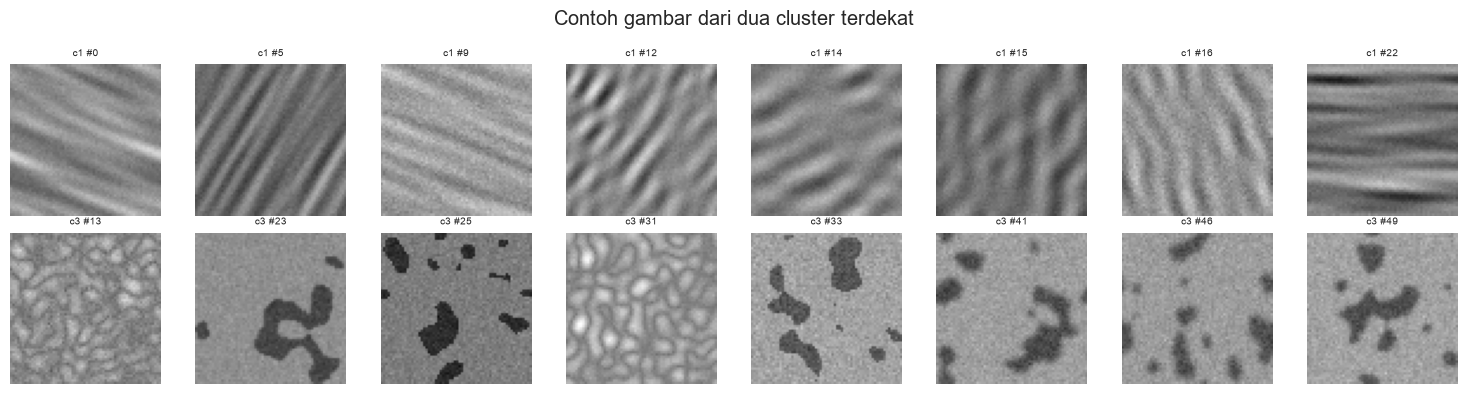

In [86]:
# ---- Cluster yang sulit dipisahkan (berdasarkan KMeans) ----
sub = np.random.default_rng(SEED).choice(N, 8000, replace=False); sil_i = silhouette_samples(E_CL16[sub], labels_km[sub]); lab_sub = labels_km[sub]
per_cl = pd.DataFrame({"cluster": range(K_SEL), "n": np.bincount(labels_km, minlength=K_SEL),
                       "silhouette rata2": [sil_i[lab_sub == c].mean() for c in range(K_SEL)],
                       "% titik batas (sil < 0.1)": [(sil_i[lab_sub == c] < 0.1).mean() * 100 for c in range(K_SEL)]})
CEN = np.stack([E_CL16[labels_km == c].mean(0) for c in range(K_SEL)])
DM = np.linalg.norm(CEN[:, None] - CEN[None], axis=2); np.fill_diagonal(DM, np.inf); a, b = np.unravel_index(np.argmin(DM), DM.shape)
per_cl["cluster tetangga terdekat"] = DM.argmin(1); per_cl["jarak ke tetangga"] = DM.min(1); print(per_cl.round(3).to_string(index=False))
print(f"\nPasangan cluster paling berdekatan: {a} dan {b} (jarak pusat = {DM[a, b]:.3f}); cluster paling tidak terpisah: {int(per_cl.loc[per_cl['silhouette rata2'].idxmin(), 'cluster'])}")

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].bar(per_cl["cluster"], per_cl["silhouette rata2"], color="#4c72b0"); ax[0].axhline(0, c="k", lw=.6); ax[0].set(title="Silhouette rata-rata per cluster", xlabel="cluster")
D_show = DM.copy(); np.fill_diagonal(D_show, 0); sns.heatmap(D_show, annot=K_SEL <= 8, fmt=".2f", cmap="viridis_r", ax=ax[1]); ax[1].set_title("Jarak antar-pusat cluster")
for c in (a, b): ax[2].plot(X_PP[labels_km == c].mean(0), label=f"cluster {c}")
ax[2].set(title="Rata-rata spektrum bersih: dua cluster terdekat", xlabel="kanal"); ax[2].legend()
plt.tight_layout(); plt.show()
if HAS_IMAGES:
    fig, ax = plt.subplots(2, 8, figsize=(15, 4))
    for r, c in enumerate((a, b)):
        for j, i in enumerate(np.where(labels_km == c)[0][:8]): ax[r, j].imshow(GAMBAR[i], cmap="gray", vmin=0, vmax=255); ax[r, j].axis("off"); ax[r, j].set_title(f"c{c} #{i}", fontsize=7)
    plt.suptitle("Contoh gambar dari dua cluster terdekat"); plt.tight_layout(); plt.show()

**Analisis cluster yang sulit dipisahkan.** Cluster yang sulit dipisahkan terlihat dari tiga petunjuk yang konsisten: **(1)** silhouette rata-rata rendah dan persentase titik batas tinggi, **(2)** pusat cluster saling berdekatan (heatmap jarak), dan **(3)** wilayah yang bertumpuk di UMAP/t-SNE.
Untuk pasangan terdekat, perhatikan **rata-rata spektrum** dan **contoh gambar** kedua cluster: bila spektrumnya hampir sama dan gambarnya yang berbeda (atau sebaliknya), pasangan itu hanya terpisah oleh **satu modality**, dan gangguan pada modality tersebut
(noise spektrum, geseran puncak, perbedaan kecerahan antar-mikroskop) langsung menimbulkan tumpang tindih. Jika pewarnaan menurut mikroskop memperlihatkan pola yang sejalan dengan cluster, itu tanda *domain shift*, bukan jenis material. Pengukurannya ada di Section 13.

# SECTION 13 — Cluster Evaluation

**ARI terhadap label referensi.** Sesuai ketentuan, label jenis material sebenarnya **tidak dibagikan**; ARI resmi dihitung dosen dari `cluster.csv`. Label referensi **tidak pernah** dipakai untuk training atau fitting di notebook ini.
Fungsi `ari_vs_reference` di bawah baru aktif bila berkas `referensi_label.csv` (kolom `id_sampel`, `label`) kebetulan tersedia, misalnya untuk simulasi internal; tanpa berkas itu, evaluasi memakai **ukuran pengganti yang sah tanpa label**:
metrik internal, **kesepakatan antar-metode (ARI)**, **kestabilan antar-seed**, **keterkaitan dengan mikroskop** (kontrol domain shift), dan **nilai tiap modality**.

In [87]:
def find_ref():
    for d in [DATA_DIR, OUTPUT_DIR, Path(".")]:
        if (Path(d) / REF_LABEL_FILE).exists(): return Path(d) / REF_LABEL_FILE
    return None

def ari_vs_reference(labels_dict):
    p = find_ref()
    if p is None:
        print(f"Label referensi ({REF_LABEL_FILE}) tidak tersedia -> ARI terhadap jenis material sebenarnya TIDAK dapat dihitung di sini (dihitung dosen)."); return None
    ref = pd.read_csv(p).set_index("id_sampel")["label"].reindex(IDS)
    assert ref.notna().all(), "label referensi tidak lengkap untuk semua id_sampel"
    return {nm: adjusted_rand_score(ref.to_numpy(), lab) for nm, lab in labels_dict.items()}      # hanya EVALUASI

METHODS = {"KMeans": labels_km, "GMM": labels_gmm, "DEC": LABELS_DEC}
print("ARI vs referensi:", ari_vs_reference(METHODS))

# ---- 13.1 Metrik internal (ruang yang sama) + keterkaitan dengan mikroskop ----
def micro_assoc(lab):
    ct = pd.crosstab(lab, MIC); chi2, p, _, _ = chi2_contingency(ct)
    return float(normalized_mutual_info_score(lab, MIC)), float(p), (ct[1] / ct.sum(1)).round(3).to_dict()

rows = []
for nm, lab in METHODS.items():
    s, db, ch = internal_metrics(E_CL16, lab); nmi_m, p_m, frac = micro_assoc(lab)
    rows.append({"metode": nm, "k": len(np.unique(lab)), "silhouette": s, "DB": db, "CH": ch, "NMI vs mikroskop": nmi_m, "p chi2 mikroskop": p_m})
EVAL = pd.DataFrame(rows).set_index("metode"); print(EVAL.round(4).to_string())
print(f"\nFraksi M2 per cluster (KMeans) - fraksi global M2 = {MIC.mean():.3f}:", micro_assoc(labels_km)[2])

Label referensi (referensi_label.csv) tidak tersedia -> ARI terhadap jenis material sebenarnya TIDAK dapat dihitung di sini (dihitung dosen).
ARI vs referensi: None
        k  silhouette      DB          CH  NMI vs mikroskop  p chi2 mikroskop
metode                                                                       
KMeans  4      0.4138  1.0688  17986.2207            0.0001            0.2658
GMM     4      0.4106  1.0951  17547.9907            0.0000            0.3889
DEC     4      0.4107  1.0948  17542.1753            0.0000            0.3615

Fraksi M2 per cluster (KMeans) - fraksi global M2 = 0.399: {0: 0.4, 1: 0.398, 2: 0.391, 3: 0.406}


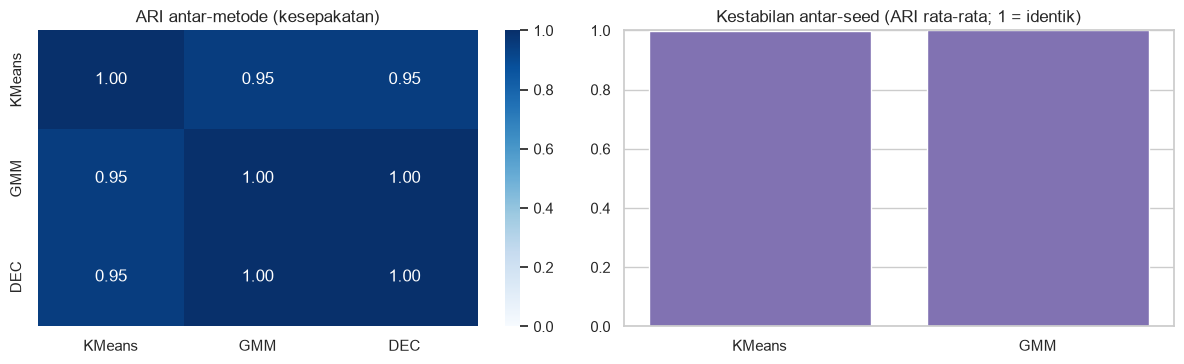

        k  silhouette      DB          CH  NMI vs mikroskop  p chi2 mikroskop  stabilitas antar-seed (ARI)
metode                                                                                                    
KMeans  4      0.4138  1.0688  17986.2207            0.0001            0.2658                       0.9993
GMM     4      0.4106  1.0951  17547.9907            0.0000            0.3889                       1.0000
DEC     4      0.4107  1.0948  17542.1753            0.0000            0.3615                          NaN


In [88]:
# ---- 13.2 Kesepakatan antar-metode dan kestabilan antar-seed ----
names = list(METHODS); AG = pd.DataFrame([[adjusted_rand_score(METHODS[a], METHODS[b]) for b in names] for a in names], index=names, columns=names)
def seed_stability(fit_predict, n=N_STAB):
    L_ = [fit_predict(SEED + 10 * s) for s in range(n)]; return float(np.mean([adjusted_rand_score(L_[i], L_[j]) for i in range(n) for j in range(i + 1, n)]))
STAB_SEED = {"KMeans": seed_stability(lambda s: KMeans(K_SEL, n_init=1, random_state=s).fit_predict(E_CL16)),
             "GMM": seed_stability(lambda s: GaussianMixture(K_SEL, covariance_type="full", n_init=1, random_state=s).fit_predict(E_CL16))}
EVAL["stabilitas antar-seed (ARI)"] = pd.Series(STAB_SEED)          # DEC: 1 kali latih (biaya); cukup dilihat dari konvergensi + ARI vs KMeans
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); sns.heatmap(AG, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[0]); ax[0].set_title("ARI antar-metode (kesepakatan)")
ax[1].bar(list(STAB_SEED), list(STAB_SEED.values()), color="#8172b2"); ax[1].set(title="Kestabilan antar-seed (ARI rata-rata; 1 = identik)", ylim=(0, 1)); plt.tight_layout(); plt.show()
print(EVAL.round(4).to_string())

               ARI vs fusi (KMeans)  NMI vs fusi  NMI vs mikroskop  silhouette (ruang modality)
Spektrum saja                 0.980        0.966             0.000                        0.471
Gambar saja                   0.292        0.394             0.112                        0.352
ARI spektrum-saja vs gambar-saja = 0.284


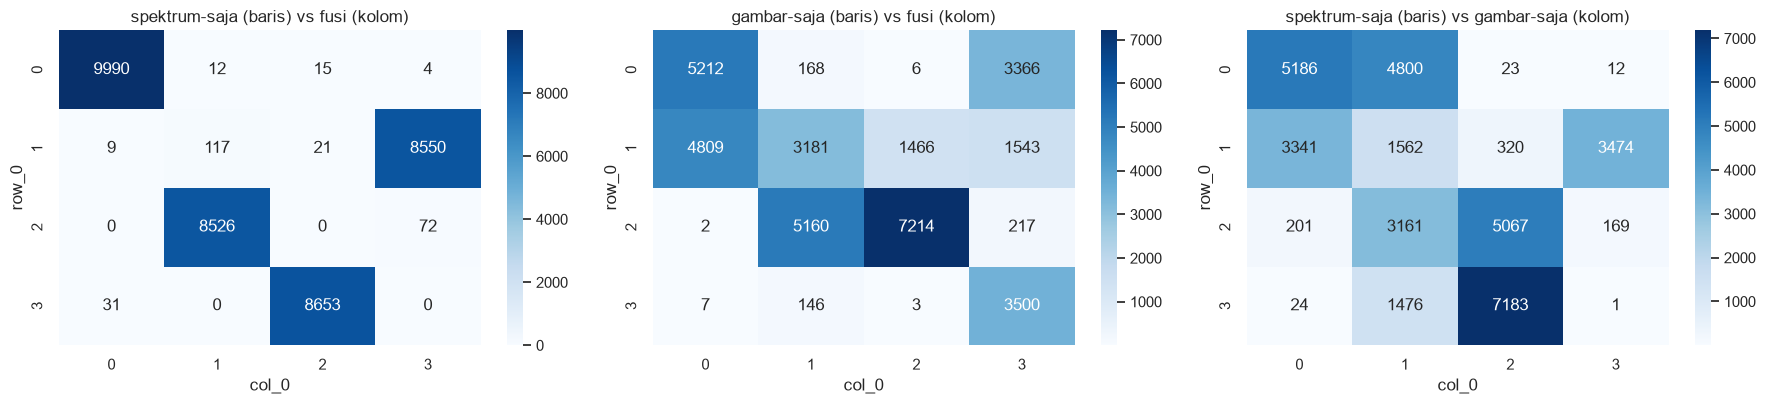

In [89]:
# ---- 13.3 Nilai tiap modality: apa yang hilang bila hanya satu modality? ----
if not HAS_IMG:
    print("Perbandingan modality DITUNDA: embedding gambar belum tersedia (Section 6).")
    MODALITY_CMP = None
else:
    lab_spec = KMeans(K_SEL, n_init=N_INIT, random_state=SEED).fit_predict(prep_for_cluster(E_SPEC))
    lab_img = KMeans(K_SEL, n_init=N_INIT, random_state=SEED).fit_predict(prep_for_cluster(E_IMG))
    ref_lab = labels_km
    MODALITY_CMP = pd.DataFrame({"ARI vs fusi (KMeans)": [adjusted_rand_score(lab_spec, ref_lab), adjusted_rand_score(lab_img, ref_lab)],
                                 "NMI vs fusi": [normalized_mutual_info_score(lab_spec, ref_lab), normalized_mutual_info_score(lab_img, ref_lab)],
                                 "NMI vs mikroskop": [normalized_mutual_info_score(lab_spec, MIC), normalized_mutual_info_score(lab_img, MIC)],
                                 "silhouette (ruang modality)": [internal_metrics(prep_for_cluster(E_SPEC), lab_spec)[0], internal_metrics(prep_for_cluster(E_IMG), lab_img)[0]]},
                                index=["Spektrum saja", "Gambar saja"])
    print(MODALITY_CMP.round(3).to_string()); print(f"ARI spektrum-saja vs gambar-saja = {adjusted_rand_score(lab_spec, lab_img):.3f}")
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
    for a_, (x, y, tt) in zip(ax, [(lab_spec, ref_lab, "spektrum-saja (baris) vs fusi (kolom)"), (lab_img, ref_lab, "gambar-saja (baris) vs fusi (kolom)"), (lab_spec, lab_img, "spektrum-saja (baris) vs gambar-saja (kolom)")]):
        sns.heatmap(pd.crosstab(x, y), annot=K_SEL <= 8, fmt="d", cmap="Blues", ax=a_); a_.set_title(tt)
    plt.tight_layout(); plt.show()

**Interpretasi.** **(1)** *Kesepakatan antar-metode* yang tinggi berarti struktur cluster kokoh terhadap pilihan algoritma; yang rendah menunjukkan wilayah ambigu. **(2)** *Kestabilan antar-seed* mendekati 1 berarti hasil tidak bergantung pada inisialisasi acak. **(3)** *NMI terhadap mikroskop*
yang kecil (dan fraksi M2 per cluster mendekati fraksi global) berarti cluster **tidak** mengikuti mikroskop; nilai besar menandakan domain shift bocor ke cluster. **(4)** Pada **crosstab modality**, sel yang tersebar (bukan satu sel dominan per baris/kolom) menunjukkan bahwa kedua modality
**membagi sampel dengan cara berbeda**: itulah informasi yang hilang bila hanya satu modality dipakai. Karena label referensi tidak tersedia, semua ini adalah **bukti tidak langsung**; ARI sebenarnya ditentukan dosen.

# SECTION 14 — Final Analysis

Metode terbaik dipilih dengan **agregasi peringkat** atas ukuran tanpa-label pada ruang yang sama: silhouette (↑), Davies-Bouldin (↓), keterkaitan dengan mikroskop (↓, domain shift), dan kestabilan antar-seed (↑, hanya untuk metode yang diulang).
**Catatan bias:** semua ukuran dihitung pada `E_CL16`, ruang tempat KMeans mengoptimalkan jaraknya, sehingga KMeans cenderung diuntungkan pada silhouette/DB; DEC belajar di latent-nya sendiri. Karena itu pilihan ini adalah keputusan terbaik **yang tersedia tanpa label**, bukan bukti keunggulan mutlak.

In [90]:
R_ = pd.DataFrame({"silhouette": EVAL["silhouette"].rank(ascending=False), "DB": EVAL["DB"].rank(ascending=True),
                   "mikroskop": EVAL["NMI vs mikroskop"].rank(ascending=True), "stabilitas": EVAL["stabilitas antar-seed (ARI)"].rank(ascending=False)})
EVAL["rata-rata peringkat"] = R_.mean(1, skipna=True)
BEST_METHOD = EVAL["rata-rata peringkat"].idxmin(); FINAL_LABELS = METHODS[BEST_METHOD].astype(int)
print(EVAL.round(4).to_string()); print(f"\nMetode terbaik (agregasi peringkat tanpa label): {BEST_METHOD} | k = {K_SEL} | mode = {MODE}")
EVAL.to_csv(OUTPUT_DIR / "evaluasi_akhir.csv"); np.save(OUTPUT_DIR / "assign_final.npy", FINAL_LABELS)

        k  silhouette      DB          CH  NMI vs mikroskop  p chi2 mikroskop  stabilitas antar-seed (ARI)  rata-rata peringkat
metode                                                                                                                         
KMeans  4      0.4138  1.0688  17986.2207            0.0001            0.2658                       0.9993                 1.75
GMM     4      0.4106  1.0951  17547.9907            0.0000            0.3889                       1.0000                 2.00
DEC     4      0.4107  1.0948  17542.1753            0.0000            0.3615                          NaN                 2.00

Metode terbaik (agregasi peringkat tanpa label): KMeans | k = 4 | mode = multimodal


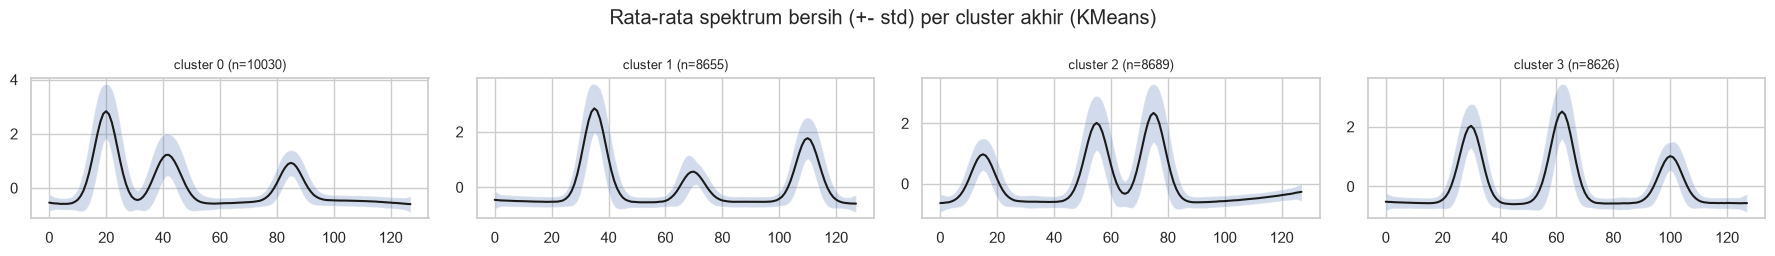

 cluster     n  % sampel posisi puncak (kanal) tinggi puncak  % M2  std geseran puncak
       0 10030     27.86                  [20]        [2.83] 40.05                2.51
       1  8655     24.04             [35, 110]  [2.84, 1.77] 39.84                2.28
       2  8689     24.14              [55, 75]  [2.01, 2.34] 39.12                2.53
       3  8626     23.96              [30, 62]  [2.03, 2.51] 40.58                2.34


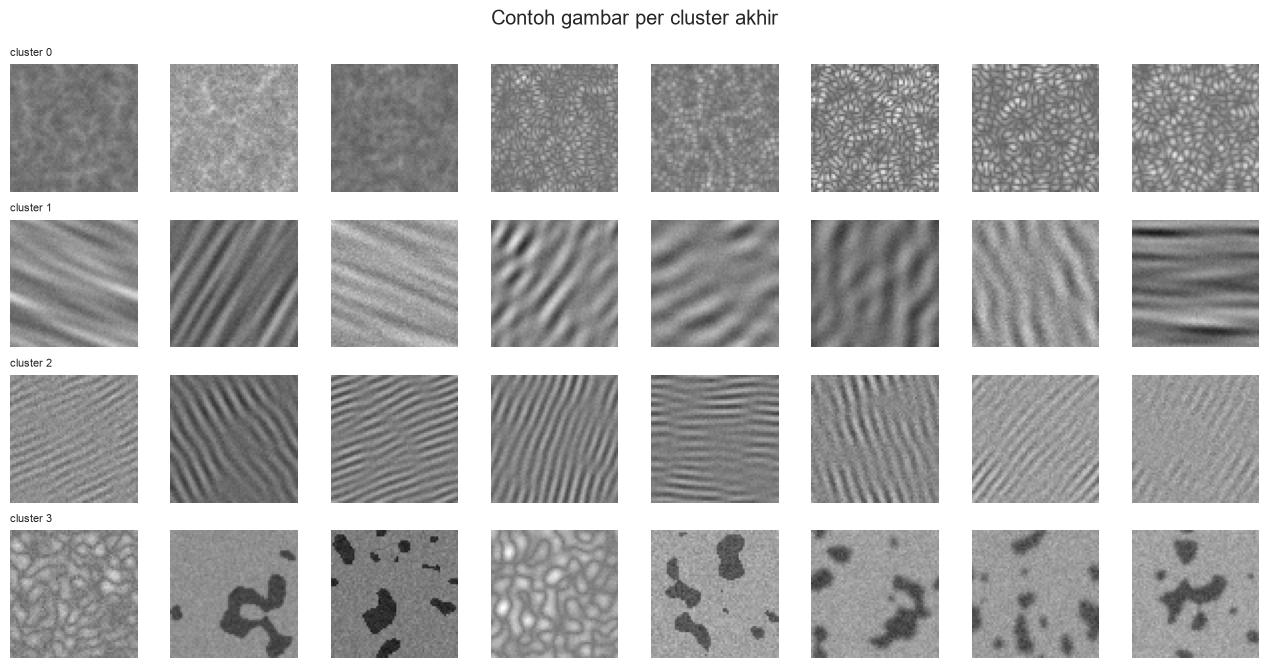

In [91]:
# ---- Karakteristik cluster akhir ----
rows = []; fig, ax = plt.subplots(int(np.ceil(K_SEL / 4)), 4, figsize=(18, 2.6 * int(np.ceil(K_SEL / 4))), squeeze=False)
for c in range(K_SEL):
    m = FINAL_LABELS == c; mean_sp = X_PP[m].mean(0); sd_sp = X_PP[m].std(0); pk, _ = find_peaks(mean_sp, height=0.5 * mean_sp.max(), distance=6)
    a_ = ax[c // 4, c % 4]; a_.plot(mean_sp, "k"); a_.fill_between(np.arange(L), mean_sp - sd_sp, mean_sp + sd_sp, alpha=.25); a_.set_title(f"cluster {c} (n={int(m.sum())})", fontsize=9)
    rows.append({"cluster": c, "n": int(m.sum()), "% sampel": m.mean() * 100, "posisi puncak (kanal)": pk.tolist(), "tinggi puncak": mean_sp[pk].round(2).tolist(), "% M2": MIC[m].mean() * 100,
                 "std geseran puncak": float(SHIFT[m].std())})
for j in range(K_SEL, ax.size): ax.ravel()[j].axis("off")
plt.suptitle(f"Rata-rata spektrum bersih (+- std) per cluster akhir ({BEST_METHOD})"); plt.tight_layout(); plt.show()
CHAR = pd.DataFrame(rows); print(CHAR.round(2).to_string(index=False)); CHAR.to_csv(OUTPUT_DIR / "karakteristik_cluster.csv", index=False)

if HAS_IMAGES:
    fig, ax = plt.subplots(K_SEL, 8, figsize=(13, 1.7 * K_SEL), squeeze=False)
    for c in range(K_SEL):
        for j, i in enumerate(np.where(FINAL_LABELS == c)[0][:8]): ax[c, j].imshow(GAMBAR[i], cmap="gray", vmin=0, vmax=255); ax[c, j].axis("off")
        ax[c, 0].set_title(f"cluster {c}", fontsize=8, loc="left")
    plt.suptitle("Contoh gambar per cluster akhir"); plt.tight_layout(); plt.show()

## Analisis dan keterbatasan
* **Karakteristik cluster.** Tabel dan grafik di atas merinci tiap cluster: ukuran, **posisi dan tinggi puncak spektrum** (penanda komposisi), proporsi mikroskop, dan contoh gambar. Cluster yang puncaknya identik tetapi gambarnya berbeda menunjukkan jenis material yang hanya dibedakan oleh gambar, dan sebaliknya.
* **Keterbatasan eksperimen.**
  1. **Tidak ada label** di tangan mahasiswa: pemilihan k, representasi, fusion, dan metode terbaik memakai ukuran internal/kestabilan, yang bisa berbeda dari ARI sebenarnya (terutama bila jenis material berbagi spektrum atau gambar).
  2. **Jumlah cluster** pada data hierarkis ambigu; silhouette cenderung memilih partisi kasar. Kestabilan membantu tetapi tidak menjamin k yang sesuai dengan jenis material sesungguhnya.
  3. **Ukuran internal dihitung di ruang `E_CL16`** (PCA 16-d), yang menguntungkan KMeans; DEC dan GMM tidak sepenuhnya dinilai secara adil.
  4. **Geseran puncak** diestimasi dengan heuristik per kelompok spektral (hanya sebagai diagnostik) dan tidak sempurna.
  5. **Satu run** untuk representasi deep learning dan DEC (biaya waktu); variasi antar-seed hanya diukur untuk KMeans/GMM.
  6. **Domain shift mikroskop** ditangani oleh image embedding Anggota 1; di sini hanya **diukur** (NMI/chi²), tidak dikoreksi.

# SECTION 15 — Export CSV

Berkas `cluster.csv` dengan kolom **`id_sampel, cluster`** (satu baris per sampel, `cluster` bilangan bulat), sesuai ketentuan. Nomor cluster boleh bebas karena penilaian memakai ARI.
Pada **mode `spektrum_saja`** (embedding gambar belum tersedia) berkas **tidak** diberi nama `cluster.csv`, supaya hasil sementara tidak terkirim sebagai hasil akhir.

In [92]:
EXPORT_NAME = "cluster.csv" if MODE == "multimodal" else "cluster_spektrum_saja_SEMENTARA.csv"
submission = pd.DataFrame({"id_sampel": IDS, "cluster": FINAL_LABELS.astype(int)})
submission.to_csv(EXPORT_NAME, index=False); submission.to_csv(OUTPUT_DIR / EXPORT_NAME, index=False)

# ---- Validasi format ----
chk = pd.read_csv(EXPORT_NAME)
assert list(chk.columns) == ["id_sampel", "cluster"], chk.columns.tolist()
assert len(chk) == N == len(meta), f"jumlah baris {len(chk)} != {N}"
assert chk["id_sampel"].is_unique and set(chk["id_sampel"]) == set(meta["id_sampel"]) and (chk["id_sampel"].to_numpy() == IDS).all()
assert pd.api.types.is_integer_dtype(chk["cluster"]) and not chk.isna().any().any()
print(f"Tersimpan: {Path(EXPORT_NAME).resolve()} | {len(chk)} baris | {chk['cluster'].nunique()} cluster | ukuran: {chk['cluster'].value_counts().sort_index().to_dict()}")
print("Baris pertama:", chk.iloc[0].tolist(), "(format: S123456,4)"); print(chk.head())
if MODE != "multimodal":
    print("\n" + "=" * 100); print("PERINGATAN: ini hasil SEMENTARA dari spektrum saja (embedding gambar Anggota 1 belum ada). JANGAN dikumpulkan sebagai cluster.csv."); print("=" * 100)
print(f"\nBerkas {EXPORT_NAME} ada di folder notebook; salinan beserta embedding/bobot model ada di {OUTPUT_DIR.resolve()}")

Tersimpan: C:\Users\Echa\Documents\UTS_DL_Clustering\kode\cluster.csv | 36000 baris | 4 cluster | ukuran: {0: 10030, 1: 8655, 2: 8689, 3: 8626}
Baris pertama: ['S966119', np.int64(1)] (format: S123456,4)
  id_sampel  cluster
0   S966119        1
1   S315633        2
2   S805122        0
3   S467543        2
4   S475842        2

Berkas cluster.csv ada di folder notebook; salinan beserta embedding/bobot model ada di C:\Users\Echa\Documents\UTS_DL_Clustering\kode\outputs


# SECTION 16 — Conclusion

In [93]:
print(f"Mode                    : {MODE}")
print(f"Representasi spektrum   : {SPEC_NAME}")
print(f"Strategi fusion         : {FUSION_NAME}")
print(f"Jumlah cluster (K_SEL)  : {K_SEL}  | pilihan per kriteria: {PICKS}")
print(f"Metode terbaik          : {BEST_METHOD}")
print(EVAL.loc[BEST_METHOD, ["silhouette", "DB", "NMI vs mikroskop"]].round(3).to_dict())
print("Berkas keluaran         :", EXPORT_NAME, "(+ embedding, bobot, assignment di", OUTPUT_DIR, ")")

Mode                    : multimodal
Representasi spektrum   : Autoencoder
Strategi fusion         : Concat skala-blok (w_gambar=0.5)
Jumlah cluster (K_SEL)  : 4  | pilihan per kriteria: {'silhouette (maks)': 5, 'Davies-Bouldin (min)': 5, 'stabilitas ARI (maks)': 3, 'Calinski-Harabasz (maks)': 4, 'BIC GMM (min)': 12}
Metode terbaik          : KMeans
{'silhouette': 0.414, 'DB': 1.069, 'NMI vs mikroskop': 0.0}
Berkas keluaran         : cluster.csv (+ embedding, bobot, assignment di outputs )


## Kesimpulan

**Temuan dari data spektrum (terverifikasi pada EDA, berlaku untuk dataset yang dibagikan):**
1. Spektrum mentah **didominasi baseline**: komponen utama pertama (±46% varians) berkorelasi ±0,99 dengan rata-rata sampel, jadi clustering langsung pada data mentah mengelompokkan menurut offset, bukan material.
2. Distorsi spektrum ada empat: **baseline** (polinomial halus), **spike** satu kanal (±seperlima sampel), **noise**, dan **geseran puncak kontinu** (std ±2 kanal, rentang ±5 kanal). Mikroskop **tidak** memengaruhi spektrum.
3. Setelah despike (selisih ke tetangga, ambang di jurang antara noise dan spike) dan koreksi baseline (polinomial dengan pemotongan iteratif), keterpisahan cluster naik tanpa label apa pun. Spektrum bersih membentuk **kelompok spektral yang jelas dengan pola puncak berbeda**.
4. Geseran puncak adalah **distorsi, bukan kelas**: ia kontinu dan unimodal di dalam tiap kelompok. Representasi yang menyimpannya (PCA, autoencoder) memecah satu material menjadi beberapa cluster; **contrastive encoder dengan augmentasi geser** dirancang untuk mengabaikannya (R² geseran pada Section 7.x).

**Metode dan jumlah cluster.** Jumlah cluster dipilih dengan **silhouette, Davies-Bouldin, dan kestabilan resampling** (didukung Calinski-Harabasz dan BIC), bukan dengan satu kriteria; clustering memakai **KMeans, GMM, dan DEC** pada embedding fusi spektrum + gambar. Hasil akhir (metode terbaik, k, metrik) tercetak di cell di atas dari run terakhir.

**Insight multimodal.** Nilai penambahan gambar dibaca dari: k terbaik dan silhouette fusi vs modality tunggal (Section 8 dan 11), serta crosstab spektrum-saja vs gambar-saja (Section 13). Bila gambar memisahkan sampel yang spektrumnya mirip, itulah informasi yang hilang pada pendekatan satu modality.

**Kelebihan.** Preprocessing per sampel tanpa label dan tanpa statistik global (tanpa kebocoran); augmentasi yang meniru distorsi nyata; pemilihan k berlapis dan terukur; pemeriksaan pairing ID dan domain shift mikroskop; embedding, bobot, dan assignment tersimpan sehingga tidak perlu training ulang; mode sementara yang tidak menulis `cluster.csv` final tanpa embedding gambar.

**Keterbatasan.** Tidak ada label, jadi ARI sebenarnya tidak dapat diperiksa; pemilihan k pada struktur hierarkis ambigu; satu run untuk model deep learning; ukuran internal dihitung pada ruang PCA 16-d yang menguntungkan KMeans; kualitas hasil akhir sangat bergantung pada **image embedding Anggota 1** (termasuk penanganan perbedaan mikroskop).

**Langkah lanjutan.** Beberapa seed dan ensemble clustering (consensus); fusion terlatih ujung-ke-ujung (loss kontrastif lintas-modality); koreksi domain shift mikroskop pada gambar; tuning `SHIFT_MAX`, `EMB_DIM`, dan bobot fusion dengan kestabilan sebagai panduan.